<div style="background:#1B2A49;padding:34px 38px;border-radius:10px;color:#ffffff;">
<div style="font-size:13px;letter-spacing:2px;color:#7FD3CF;text-transform:uppercase;">Veterinary AI · Thoracic Radiology · Multi-Label Deep Learning</div>
<h1 style="color:#ffffff;margin:10px 0 6px 0;font-size:34px;">VetXRay: Fine-Tuning Seven Architectures for 17 Thoracic Findings in Dogs and Cats</h1>
<div style="font-size:15px;color:#D6E4F0;max-width:900px;line-height:1.55;">
A reproducible study on 9,882 annotated canine and feline radiographs: DICOM processing, animal-level leakage control,
two custom CNNs trained from scratch, five transfer-learning models, Optuna tuning, calibrated per-finding thresholds,
and the export of a single validated model for the PetAI inference module.
</div>
</div>

## 1 · Introduction and Objectives

**A simple picture first.** A radiologist looking at a chest film does not answer one question ("which disease is it?").
They answer seventeen independent questions at once: *Is the heart enlarged? Is there fluid? Is there a mass?* Several
answers can be "yes" on the same film. That is exactly a **multi-label** problem: each finding gets its own yes/no
probability, produced by its own sigmoid output, and the probabilities do **not** have to sum to one.

**Objectives of this notebook**

| # | Objective | Where |
|---|---|---|
| 1 | Audit the VetXRay release (labels, DICOM headers, duplicates, exclusions, leakage risks) | §3 |
| 2 | Build an animal-level, label-stratified train / validation / test split | §5 |
| 3 | Implement a faithful DICOM → tensor pipeline shared by training and inference | §4 |
| 4 | Train two custom CNNs from scratch as educational baselines | §7 |
| 5 | Fine-tune five pretrained models with a two-stage protocol | §8 |
| 6 | Tune the three PetAI candidates with Optuna under a fixed budget | §9 |
| 7 | Compare all models on validation, then report the untouched test set once | §10–§12 |
| 8 | Export one model (CLIP, HieraDet or EfficientNet-B3) for `petai_xray_inference.py` | §13 |

**Model families**

| Model | Role | Pretraining | Why it is here |
|---|---|---|---|
| Custom CNN (VGG-style) | Educational baseline | none | Shows what plain convolution stacks learn from ~5k images |
| Custom Residual CNN + SE | Educational baseline | none | Isolates the effect of skip connections and channel attention |
| CLIP ViT-B/32 (vision tower) | **PetAI candidate** | 400M image–text pairs | Strong general visual features; tests a transformer with coarse 32-px patches |
| HieraDet-D Small (DINOv2 → iNat21) | **PetAI candidate** | self-supervised + fine-grained biology | Hierarchical ViT with multi-scale features; fine-grained natural-world pretraining |
| EfficientNet-B3 | **PetAI candidate** | ImageNet-1k | Compute-efficient CNN; a common deployment choice |
| DenseNet-121 | Comparison | ImageNet-1k | Classic radiology baseline (CheXNet lineage; used in the original VetXRay papers) |
| ConvNeXt-Tiny | Comparison | ImageNet-22k → 1k | A modernised CNN that borrows transformer design choices |

> **Scope statement.** This is exploratory research on a single-institution dataset. No model in this notebook is a
> clinically validated diagnostic device.

## 2 · Scientific Background

The table records how each source changed a concrete decision in this notebook. Sources marked *full text* were read
beyond the abstract (methods and results); *documentation / source code* means the official docs or repository were
inspected.

| Reference | Concept used | Practical decision in this notebook | Limitation / caveat |
|---|---|---|---|
| [Banzato et al., 2021, *Sci. Rep.* 11:3964](https://pmc.ncbi.nlm.nih.gov/articles/PMC7889925) (full text) | ResNet-50 / DenseNet-121 on canine LL radiographs, 224 px, BCE, Adam, 8:1:1 split | DenseNet-121 kept as a comparison model; BCE loss; rare findings acknowledged as untrainable. Reported AUCs (e.g. pleural effusion 0.96, cardiomegaly 0.92) are a *reference*, not a target | Image-level random split and LL-only images; their numbers are not directly comparable to an animal-level split over all projections |
| [Banzato et al., 2021, *Front. Vet. Sci.* 8:731936](https://pmc.ncbi.nlm.nih.gov/articles/PMC8554083) (full text) | Feline radiographs, ResNet-50 vs Inception-V3; mass AUC ≈ 0.58 | Mass is expected to be hard; species-specific results are reported separately | Small feline set; no cross-validation |
| [Banzato et al., 2023, *Sci. Rep.* 13](https://pmc.ncbi.nlm.nih.gov/articles/PMC10562412) (full text) | AI-based image-quality grading | Quality tags are analysed as a covariate (performance on `correct` vs `positioning`/`exposure` images) | Quality labels are single-reader in this release |
| [Burti et al., 2020, *Vet. J.*](https://research.unipd.it/handle/11577/3348309) (institutional record) | CNNs for canine cardiomegaly | Cardiomegaly is the most frequent finding and is used for calibration and Grad-CAM case studies | Not read in full; cited for context only |
| [VetXRay record, Zenodo 10.5281/zenodo.19051776](https://zenodo.org/records/19051776) and [`validate.py`](https://github.com/MWod/VetXRay_Dataset) (source code) | Official 17-finding vocabulary, quality vocabulary, PatientID retained by design | The label list below is taken verbatim from `validate.py`; PatientID is used for grouping | — |
| [Google Deep Learning Tuning Playbook](https://github.com/google-research/tuning_playbook) | Fix the pipeline first, then tune; separate scientific vs nuisance hyperparameters; budgeted search | Baseline protocol identical for all models; Optuna only on nuisance hyperparameters of the 3 candidates, with a stated trial budget | Playbook targets larger compute budgets |
| [PyTorch transfer-learning tutorial](https://docs.pytorch.org/tutorials/beginner/transfer_learning_tutorial.html) | Feature extraction vs fine-tuning | Stage 1 = frozen backbone (head only); Stage 2 = partial / full unfreezing with differential learning rates | — |
| [CLIP, Radford et al., 2021](https://arxiv.org/abs/2103.00020) | Contrastive image–text pretraining | Only the vision tower is used with a supervised 17-way sigmoid head (not zero-shot text matching); positional embeddings interpolated to 384 px | Pretrained on natural images; 32-px patches are coarse for subtle opacities |
| [Hiera, Ryali et al., 2023](https://arxiv.org/abs/2306.00989) · [model card](https://huggingface.co/birder-project/hieradet_d_small_dino-v2-inat21) · [Birder source](https://github.com/birder-project/birder) | Hierarchical ViT; 384 px, 41.6M params, 768-d embedding; `freeze_stages`, `reset_classifier` | Loaded through `birder.load_pretrained_model`; stage-wise unfreezing; gradient checkpointing for 8 GB GPUs | Requires Python ≥ 3.11 and a recent PyTorch |
| [DINOv2, Oquab et al., 2023](https://arxiv.org/abs/2304.07193) | Self-supervised features transfer across domains | Motivates HieraDet as a candidate | — |
| [EfficientNet, Tan & Le, 2019](https://proceedings.mlr.press/v97/tan19a.html) | Compound scaling | EfficientNet-B3 trained at 384 px (native ≈ 300–320 px) | — |
| [DenseNet, Huang et al., 2017](https://arxiv.org/abs/1608.06993) · [ConvNeXt, Liu et al., 2022](https://arxiv.org/abs/2201.03545) · [ResNet, He et al., 2016](https://arxiv.org/abs/1512.03385) | Dense / modernised / residual connectivity | Comparison models and the residual design of the custom CNN | — |
| [Optuna documentation](https://optuna.readthedocs.io/) | TPE sampler, median pruning, persistent studies | SQLite-backed studies that can resume across sessions | — |
| [scikit-learn metrics](https://scikit-learn.org/stable/modules/model_evaluation.html) | Average precision, ROC-AUC, Brier score | Macro PR-AUC over well-supported findings is the primary metric | AP is undefined when a split has no positives |

**Agent skills consulted while designing the study** (third-party guidance, reviewed before use):
`medical-imaging-dataset-auditor` (patient/scanner leakage checklist, duplicate detection) ·
`imaging-study-design` and `ml-researcher` (confound list, "most imbalance problems are threshold problems",
resample only the training fold) · `dicom-processing` (photometric handling, PHI awareness) ·
`ml-hyperparameter-tuning` and `ml-model-evaluation` (pruning, seeds per trial, validation-only thresholds, bootstrap CIs) ·
`engineering-ml-engineer` (its LLM-oriented LoRA rules were judged not applicable to CNN/ViT image classifiers).

## 0 · Configuration and Environment

Everything that changes between a quick test and a full experiment lives in this one cell.

* **`RUN_MODE = "SMOKE"`** runs every stage on ~100 real images, one epoch, three batches. It proves the code paths work.
  Its numbers are **technical checks only** and are written to a separate folder so they can never be confused with results.
* **`RUN_MODE = "FULL"`** runs the real study. Each model is trained once and its results are saved; re-running a cell
  loads the saved run instead of retraining, so the study can be completed over several sessions.

The notebook detects Kaggle automatically. On a local machine it reads the original ZIP archives directly, so the
41 GB of DICOMs never have to be extracted.

In [1]:
import os, sys, io, re, json, time, math, random, zipfile, hashlib, platform, warnings, threading, importlib
from pathlib import Path
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=UserWarning, module="pydicom")

# ----------------------------------------------------------------------------- run control
RUN_MODE = os.environ.get("VETXRAY_RUN_MODE", "SMOKE").upper()   # "SMOKE" or "FULL"
ENV_OVERRIDE = os.environ.get("VETXRAY_ENV")                     # None -> auto, or "local" / "kaggle"
SEED = 42

# ----------------------------------------------------------------------------- environment & paths
def detect_env():
    if ENV_OVERRIDE:
        return ENV_OVERRIDE.lower()
    return "kaggle" if Path("/kaggle/input").exists() else "local"

ENV = detect_env()

def _find_kaggle_input(marker):
    for p in Path("/kaggle/input").rglob(marker):
        return p.parent
    return None

if ENV == "kaggle":
    DATA_DIR = Path(os.environ.get("VETXRAY_DATA_DIR") or (_find_kaggle_input("File list with tags.xlsx") or "/kaggle/input"))
    PRECOMPUTED_CACHE = _find_kaggle_input("cache_index.csv")    # optional: an uploaded preprocessed cache
    WORK_DIR = Path("/kaggle/working/vetxray_work")
    PROJECT_DIR = Path("/kaggle/working")
else:
    DATA_DIR = Path(os.environ.get("VETXRAY_DATA_DIR", r"G:\VetXRay_2026"))
    PRECOMPUTED_CACHE = None
    WORK_DIR = Path(os.environ.get("VETXRAY_WORK_DIR", r"G:\VetXRay_cache"))   # caches, runs, weights: outside the project
    PROJECT_DIR = Path(os.environ.get("VETXRAY_PROJECT_DIR", r"G:\Vet_XRay_AI"))

XLSX_PATH = DATA_DIR / "File list with tags.xlsx"
CACHE_ONLY = not XLSX_PATH.exists()   # e.g. Kaggle with only the uploaded cache + anonymous metadata: no spreadsheet, no DICOMs
_kmeta = _find_kaggle_input("vetxray_metadata.csv") if ENV == "kaggle" else None
META_CSV = (Path(_kmeta) / "vetxray_metadata.csv") if _kmeta else WORK_DIR / "kaggle_dataset" / "vetxray_metadata.csv"
CACHE_DIR = Path(PRECOMPUTED_CACHE) if PRECOMPUTED_CACHE else WORK_DIR / "cache"
RUNS_DIR = WORK_DIR / ("runs_full" if RUN_MODE == "FULL" else "runs_smoke")
PETAI_CKPT = PROJECT_DIR / "checkpoints" / "petai_xray_best.pt"
for d in (WORK_DIR, WORK_DIR / "cache", RUNS_DIR, WORK_DIR / "pretrained", WORK_DIR / "hf_cache"):
    d.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("HF_HOME", str(WORK_DIR / "hf_cache"))      # keep downloaded weights off the system drive
os.environ.setdefault("TORCH_HOME", str(WORK_DIR / "torch_cache"))

# ----------------------------------------------------------------------------- study design constants
TRAIN_SIZE = 384            # common input resolution for all seven models (fair comparison)
MIN_POS_CORE = 70           # findings with >= 70 positive images form the primary ("core") metric
SPLIT_FRACS = (0.70, 0.15, 0.15)
SMOKE_N = 96                # images used in SMOKE mode (48 / 24 / 24)

# ----------------------------------------------------------------------------- visual identity
NAVY, TEAL, BLUE, AMBER, MAGENTA, GREY, LIGHT = "#1B2A49", "#1A9E9A", "#2E5FA8", "#C9821A", "#B5446E", "#A3ADB8", "#EEF2F6"
SPLIT_COLORS = {"train": BLUE, "val": TEAL, "test": AMBER}
SPECIES_COLORS = {"Dog": BLUE, "Cat": AMBER}
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 150, "font.size": 10.5, "axes.titlesize": 13, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "axes.labelcolor": "#33415C", "axes.edgecolor": "#C7CED6", "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#E6EAEE", "grid.linewidth": 0.8,
    "xtick.color": "#55627A", "ytick.color": "#55627A", "legend.frameon": False, "figure.facecolor": "white",
})

def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); os.environ["PYTHONHASHSEED"] = str(seed)
    try:
        import torch
        torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    except ImportError:
        pass

seed_everything()
print(f"ENV={ENV} | RUN_MODE={RUN_MODE} | CACHE_ONLY={CACHE_ONLY}\nDATA_DIR={DATA_DIR}\nWORK_DIR={WORK_DIR}\nPROJECT_DIR={PROJECT_DIR}")

ENV=local | RUN_MODE=FULL | CACHE_ONLY=False
DATA_DIR=G:\VetXRay_2026
WORK_DIR=G:\VetXRay_cache
PROJECT_DIR=G:\Vet_XRay_AI


### 0.1 · Environment report

Versions are printed here instead of in a `requirements.txt`, so the notebook itself documents how it was run.

**Local setup used for this study (Windows, VS Code + Jupyter):**
```
py -3.12 -m venv .venv
.venv\Scripts\python -m pip install torch torchvision --index-url https://download.pytorch.org/whl/cu128
.venv\Scripts\python -m pip install timm transformers birder optuna pydicom pandas openpyxl scikit-learn matplotlib seaborn torchinfo ipykernel
```

In [2]:
import shutil, importlib.metadata as md

def _ver(pkg):
    try:
        return md.version(pkg)
    except md.PackageNotFoundError:
        return "not installed"

env_rows = [("python", platform.python_version()), ("platform", platform.platform())]
env_rows += [(p, _ver(p)) for p in ["torch", "torchvision", "timm", "transformers", "birder", "optuna", "pydicom",
                                     "numpy", "pandas", "scikit-learn", "matplotlib", "seaborn", "Pillow", "torchinfo"]]
try:
    import torch
    env_rows.append(("cuda available", str(torch.cuda.is_available())))
    if torch.cuda.is_available():
        p = torch.cuda.get_device_properties(0)
        free, total = torch.cuda.mem_get_info()
        env_rows += [("gpu", p.name), ("cuda (torch build)", torch.version.cuda),
                     ("vram total / free (GB)", f"{total/1e9:.1f} / {free/1e9:.1f}")]
except ImportError:
    env_rows.append(("torch", "NOT INSTALLED - modelling sections cannot run"))
try:
    import psutil
    vm = psutil.virtual_memory(); env_rows.append(("ram total / available (GB)", f"{vm.total/1e9:.1f} / {vm.available/1e9:.1f}"))
except ImportError:
    pass
du = shutil.disk_usage(WORK_DIR)
env_rows.append(("free disk at WORK_DIR (GB)", f"{du.free/1e9:.0f}"))
display(pd.DataFrame(env_rows, columns=["component", "value"]).set_index("component"))

,value
component,
python,3.12.9
platform,Windows-11-10.0.26300-SP0
torch,2.11.0+cu128
torchvision,0.26.0+cu128
timm,1.0.30
transformers,5.19.0
birder,0.8.3
optuna,5.0.0
pydicom,3.0.2


## 3 · Dataset Audit

### 3.1 · Annotation spreadsheet

The spreadsheet has one row per radiograph: file name, animal name, breed, species, projection, a quality tag and a
`|`-separated finding list (`TAG`). The official vocabulary from `validate.py` is used verbatim. `no_finding` and
`exclude` are *meta tags*, not findings.

> The `PatientName` column (the animal's given name) is used **internally only** to link radiographs of the same animal.
> It is never displayed in this notebook.

In [3]:
FINDINGS = sorted([  # official vocabulary - VetXRay_Dataset/validate.py
    "alveolar_pattern", "bronchial_pattern", "cardiomegaly", "costal_fracture", "diaphragmatic_hernia",
    "foreign_body", "fracture", "hernia", "interstitial_pattern", "mass", "megaesophagus", "pleural_effusion",
    "pleural_mineralization", "pneumoderma", "pneumomediastinum", "pneumothorax", "tracheal_collapse"])
META_TAGS = {"no_finding", "exclude"}
QUALITY_VALUES = {"correct", "overexposed", "underexposed", "positioning", "exclude"}
assert len(FINDINGS) == 17

FINDING_INFO = {  # short veterinary descriptions used in the galleries
    "alveolar_pattern": "Air spaces filled with fluid/cells: fluffy opacities, air bronchograms (pneumonia, oedema, haemorrhage).",
    "bronchial_pattern": "Thickened bronchial walls: 'donuts' and 'tram lines' (chronic bronchitis, feline asthma).",
    "cardiomegaly": "Enlarged cardiac silhouette relative to the thorax (e.g. vertebral heart score above breed reference).",
    "costal_fracture": "Fracture of a rib.",
    "diaphragmatic_hernia": "Abdominal organs displaced into the thorax through a diaphragmatic defect.",
    "foreign_body": "Radiopaque object in airway, oesophagus or thorax.",
    "fracture": "Fracture of a thoracic skeletal structure other than ribs (e.g. vertebra, sternum).",
    "hernia": "Herniation other than diaphragmatic (e.g. peritoneopericardial, hiatal).",
    "interstitial_pattern": "Increased hazy/reticular or nodular lung opacity that does not efface vessels.",
    "mass": "Focal soft-tissue opacity: pulmonary or mediastinal mass, nodule(s).",
    "megaesophagus": "Dilated oesophagus visible as a gas- or fluid-filled tube in the dorsal thorax.",
    "pleural_effusion": "Fluid in the pleural space: interlobar fissures, rounded lung margins, effaced heart.",
    "pleural_mineralization": "Mineral opacities of the pleura (often incidental in older dogs).",
    "pneumoderma": "Gas within the subcutaneous tissues.",
    "pneumomediastinum": "Free gas in the mediastinum outlining vessels and the oesophagus.",
    "pneumothorax": "Free air in the pleural space; heart elevated from the sternum on lateral views.",
    "tracheal_collapse": "Dynamic dorsoventral narrowing of the trachea (toy breeds).",
}

def split_tags(s):
    return [t.strip() for t in str(s).split("|") if t.strip()] if pd.notna(s) else []

if not CACHE_ONLY:
    ann = pd.read_excel(XLSX_PATH, engine="openpyxl")
    ann["species"] = ann["specie"].astype(str).str.strip().str.title().where(ann["specie"].notna(), None)
    ann["projection"] = ann["Projection"].astype(str).str.strip().str.upper()
    ann["quality"] = ann["Quality"].astype(str).str.strip().str.lower()
    ann["tags"] = ann["TAG"].apply(split_tags)
    unknown = sorted({t for ts in ann["tags"] for t in ts} - set(FINDINGS) - META_TAGS)
    print(f"rows: {len(ann):,} | unique file names: {ann['FileName'].nunique():,} | unknown TAG tokens: {unknown or 'none'}")
    display(ann[["FileName", "breed", "species", "projection", "quality", "TAG"]].head(5))

rows: 9,973 | unique file names: 9,971 | unknown TAG tokens: none


,FileName,breed,species,projection,quality,TAG
0,IM-0015-0001-0001.dcm,Airedale Terrier,Dog,LL,correct,bronchial_pattern|interstitial_pattern|cardiom...
1,IM-0015-0001-0002.dcm,Boxer,Dog,DV,correct,no_finding
2,IM-0015-0001-0003.dcm,Mixed Breed,Dog,DV,correct,alveolar_pattern|mass
3,IM-0015-0001-0004.dcm,Mixed Breed,Dog,DV,correct,no_finding
4,IM-0015-0001-0005.dcm,European Shorthair,Cat,LL,correct,no_finding


### 3.2 · DICOM inventory and header scan

The archives are indexed without extraction. Only the header of each file is read (`stop_before_pixels=True`), which
yields the animal identifier, scanner, photometric interpretation, bit depth and matrix size for every image. The scan
is cached in `WORK_DIR` (~2 minutes the first time).

In [4]:
if CACHE_ONLY:
    src = None   # no DICOMs in this environment: everything is served from the cache + metadata CSV
else:
    import pydicom

    class DicomSource:
        """Index *.dcm files either inside RX_*.zip archives or in plain folders; read them by file name.
        Each worker thread keeps its own ZipFile handle (ZipFile objects are not thread-safe)."""

        def __init__(self, root):
            self.root = Path(root)
            self.index = {}   # FileName -> ("zip", zip_path, member) | ("file", path)
            for zp in sorted(self.root.glob("*.zip")):
                with zipfile.ZipFile(zp) as z:
                    for m in z.namelist():
                        if m.lower().endswith(".dcm") and "__MACOSX" not in m:
                            self.index.setdefault(Path(m).name, ("zip", str(zp), m))
            for p in self.root.rglob("*.dcm"):
                if "__MACOSX" not in p.parts:
                    self.index.setdefault(p.name, ("file", str(p)))
            self._local = threading.local()

        def _zip(self, path):
            cache = getattr(self._local, "zips", None)
            if cache is None:
                cache = self._local.zips = {}
            if path not in cache:
                cache[path] = zipfile.ZipFile(path)
            return cache[path]

        def open(self, name):
            ref = self.index[name]
            if ref[0] == "zip":
                return io.BytesIO(self._zip(ref[1]).read(ref[2]))
            return open(ref[1], "rb")

        def read(self, name, header_only=False):
            with self.open(name) as fh:
                return pydicom.dcmread(fh, stop_before_pixels=header_only, force=True)

    src = DicomSource(DATA_DIR)
    print(f"DICOM files indexed: {len(src.index):,}")

    HEADER_FIELDS = ["PatientID", "Manufacturer", "PhotometricInterpretation", "BitsStored", "Rows", "Columns",
                     "WindowCenter", "WindowWidth", "Modality", "StudyDate"]

    def _header_row(name):
        try:
            ds = src.read(name, header_only=True)
            row = {"FileName": name}
            for f in HEADER_FIELDS:
                v = ds.get(f, None)
                if isinstance(v, pydicom.multival.MultiValue):
                    v = v[0]
                row[f] = None if v is None else str(v)
            return row
        except Exception as e:  # unreadable file -> recorded, not hidden
            return {"FileName": name, "error": repr(e)[:120]}

    hdr_path = WORK_DIR / "dicom_headers.csv"
    if hdr_path.exists():
        hdr = pd.read_csv(hdr_path, dtype=str)
    else:
        t0 = time.time()
        with ThreadPoolExecutor(max_workers=8) as ex:
            hdr = pd.DataFrame(list(ex.map(_header_row, sorted(src.index))))
        hdr.to_csv(hdr_path, index=False)
        print(f"header scan: {time.time()-t0:.0f}s")
    if "error" not in hdr:
        hdr["error"] = np.nan
    hdr["scanner"] = hdr["Manufacturer"].fillna("unknown").str.split().str[0].str.title()
    for c in ["BitsStored", "Rows", "Columns"]:
        hdr[c] = pd.to_numeric(hdr[c], errors="coerce")
    print(f"headers: {len(hdr):,} | unreadable: {hdr['error'].notna().sum()}")
    display(hdr.groupby(["scanner", "PhotometricInterpretation", "BitsStored"]).size().rename("images").to_frame())
    display(hdr.groupby(["WindowCenter", "WindowWidth"]).size().rename("images").sort_values(ascending=False).head(6).to_frame())

DICOM files indexed: 10,234
headers: 10,234 | unreadable: 0


images
scanner    PhotometricInterpretation BitsStored        
Carestream MONOCHROME1               12              98
                                     16               2
           MONOCHROME2               8             6895
Fuji       MONOCHROME1               14            3239

,,images
WindowCenter,WindowWidth,
127,256,6895
8192,16384,3239
2048,4096,98
23379,29896,1
38042,53990,1


**Reading the header tables.** Two acquisition systems are present: Carestream (8-bit, `MONOCHROME2`) and Fuji (14-bit,
`MONOCHROME1`, i.e. *inverted*: high values are dark). The stored VOI window simply spans the full bit range, so it
contains no clinical windowing. Two consequences follow: the photometric inversion must be applied explicitly, and the
scanner is a potential **shortcut** (a model could learn "Fuji-looking image" instead of anatomy). Section 12 checks
performance per scanner for this reason.

### 3.3 · Inclusion criteria and audit log

Every exclusion is counted, with its reason, before any modelling. Rows are removed in this order:

1. file names that appear twice in the spreadsheet with conflicting tags,
2. rows whose DICOM is missing or unreadable,
3. species other than dog or cat (fewer than 100 exotic images: not enough to learn from),
4. images the radiologist marked `exclude` (in `TAG` or `Quality`).

`no_finding` is *derived* (no positive finding) rather than trusted, because it co-occurs with real findings in a
small number of rows.

In [5]:
if CACHE_ONLY:
    # cache-only environment: restore the identical table (same rows, order, split, group ids) from the anonymous CSV
    df = pd.read_csv(META_CSV, dtype={"StudyDate": str})
    df["tags"] = df["tags"].apply(split_tags)
    Y = np.array([[f in t for f in FINDINGS] for t in df["tags"]], dtype=np.float32)
    df["n_findings"] = Y.sum(1).astype(int)
    df["no_finding"] = df["n_findings"] == 0
    df["quality_group"] = df["quality"].replace({"underexposed": "exposure", "overexposed": "exposure"})
    print(f"loaded anonymous metadata: {len(df):,} images, {df['group'].nunique():,} animal groups (no patient identifiers present)")
else:
    dup_names = ann["FileName"][ann["FileName"].duplicated(keep=False)]
    bad_hdr = set(hdr.loc[hdr["error"].notna(), "FileName"])
    meta = ann.merge(hdr.drop(columns=["error"]), on="FileName", how="left")
    reasons = pd.Series("included", index=meta.index)
    reasons[meta["FileName"].isin(dup_names)] = "duplicate file name (conflicting tags)"
    reasons[(reasons == "included") & (~meta["FileName"].isin(src.index) | meta["FileName"].isin(bad_hdr))] = "DICOM missing / unreadable"
    reasons[(reasons == "included") & (~meta["species"].isin(["Dog", "Cat"]))] = "species not dog/cat"
    excl = meta["tags"].apply(lambda t: "exclude" in t) | (meta["quality"] == "exclude")
    reasons[(reasons == "included") & excl] = "radiologist: exclude"
    meta["inclusion"] = reasons
    audit = meta["inclusion"].value_counts().rename("rows").to_frame()
    audit["share"] = (audit["rows"] / len(meta)).map("{:.1%}".format)
    display(audit)
    contradictory = meta["tags"].apply(lambda t: "no_finding" in t and any(x in FINDINGS for x in t)).sum()
    print(f"rows tagged no_finding AND a finding: {contradictory} (resolved by deriving no_finding)")
    print(f"DICOMs on disk without a spreadsheet row: {len(set(src.index) - set(ann['FileName'])):,} (ignored)")

    df = meta[meta["inclusion"] == "included"].reset_index(drop=True)
    Y = np.array([[f in t for f in FINDINGS] for t in df["tags"]], dtype=np.float32)
    df["n_findings"] = Y.sum(1).astype(int)
    df["no_finding"] = df["n_findings"] == 0
    df["quality_group"] = df["quality"].replace({"underexposed": "exposure", "overexposed": "exposure"})
    print(f"\nincluded images: {len(df):,}  (dogs {int((df.species=='Dog').sum()):,} | cats {int((df.species=='Cat').sum()):,})")

,rows,share
inclusion,,
included,7648,76.7%
radiologist: exclude,2230,22.4%
species not dog/cat,90,0.9%
duplicate file name (conflicting tags),4,0.0%
DICOM missing / unreadable,1,0.0%


rows tagged no_finding AND a finding: 103 (resolved by deriving no_finding)
DICOMs on disk without a spreadsheet row: 264 (ignored)

included images: 7,648  (dogs 5,997 | cats 1,651)


### 3.4 · Which images belong to the same animal?

Patient leakage happens when two radiographs of the **same animal** (e.g. the lateral and the dorsoventral view taken
minutes apart) end up in training and test. The model can then recognise the animal instead of the disease, and the test
score is inflated.

A conservative grouping is used: two images belong to the same group if they share the DICOM `PatientID` **or** the same
(animal name, breed, species). Groups are the connected components of this graph (union-find). This may merge a few
different animals that happen to share a name and breed, which is the safe direction of error.

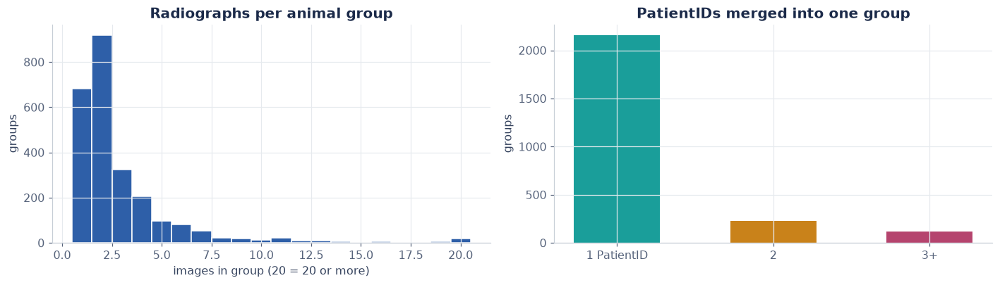

2,505 animal groups | median 2 images/group | largest 67 images (0.9% of the data) | single-image groups: 683


In [6]:
if not CACHE_ONLY:
    parent = {}
    def _find(x):
        parent.setdefault(x, x)
        while parent[x] != x:
            parent[x] = parent[parent[x]]; x = parent[x]
        return x
    def _union(a, b):
        parent[_find(a)] = _find(b)

    for fn, pid, name, breed, sp in df[["FileName", "PatientID", "PatientName", "breed", "species"]].itertuples(index=False):
        node = "img:" + fn
        _union(node, f"pid:{pid}")
        _union(node, f"nm:{str(name).strip().lower()}|{str(breed).strip().lower()}|{sp}")
    roots = {r: i for i, r in enumerate(sorted({_find("img:" + f) for f in df["FileName"]}))}
    df["group"] = [roots[_find("img:" + f)] for f in df["FileName"]]
    df = df.drop(columns=["PatientName"])            # identifier no longer needed
    meta = meta.drop(columns=["PatientName"])

    gsize = df.groupby("group").size()
    fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
    ax[0].hist(gsize.clip(upper=20), bins=np.arange(0.5, 21.5), color=BLUE, edgecolor="white")
    ax[0].set(title="Radiographs per animal group", xlabel="images in group (20 = 20 or more)", ylabel="groups")
    pid_per_group = df.groupby("group")["PatientID"].nunique()
    ax[1].bar(["1 PatientID", "2", "3+"], [(pid_per_group == 1).sum(), (pid_per_group == 2).sum(), (pid_per_group >= 3).sum()],
              color=[TEAL, AMBER, MAGENTA], width=0.55)
    ax[1].set(title="PatientIDs merged into one group", ylabel="groups")
    plt.tight_layout(); plt.show()
    print(f"{len(gsize):,} animal groups | median {gsize.median():.0f} images/group | largest {gsize.max()} images "
          f"({gsize.max()/len(df):.1%} of the data) | single-image groups: {(gsize == 1).sum():,}")

Most animals contribute two or three views, which is exactly why an image-level random split would leak. Splitting by
group keeps every view of an animal inside a single partition.

### 3.5 · The 17 findings in numbers

In [7]:
pos = pd.Series(Y.sum(0).astype(int), index=FINDINGS)
lab = pd.DataFrame({
    "positive": pos,
    "negative": len(df) - pos,
    "uncertain": 0,
    "dogs +": [int(Y[(df.species == "Dog").values, i].sum()) for i in range(17)],
    "cats +": [int(Y[(df.species == "Cat").values, i].sum()) for i in range(17)],
    "animals +": [df.loc[Y[:, i] > 0, "group"].nunique() for i in range(17)],
    "prevalence": (pos / len(df)).map("{:.2%}".format),
}).sort_values("positive", ascending=False)
CORE = [f for f in FINDINGS if pos[f] >= MIN_POS_CORE]
RARE = [f for f in FINDINGS if f not in CORE]
lab["tier"] = ["core" if f in CORE else "rare (reported, not ranked)" for f in lab.index]
display(lab)
print(f"core findings ({len(CORE)}): {CORE}\nrare findings ({len(RARE)}): {RARE}")

,positive,negative,uncertain,dogs +,cats +,animals +,prevalence,tier
cardiomegaly,1729,5919,0,1444,285,687,22.61%,core
alveolar_pattern,1024,6624,0,714,310,465,13.39%,core
bronchial_pattern,696,6952,0,485,211,401,9.10%,core
pleural_effusion,464,7184,0,248,216,197,6.07%,core
mass,433,7215,0,335,98,229,5.66%,core
interstitial_pattern,391,7257,0,296,95,245,5.11%,core
pneumothorax,161,7487,0,108,53,75,2.11%,core
pleural_mineralization,122,7526,0,120,2,103,1.60%,core
megaesophagus,105,7543,0,87,18,51,1.37%,core
foreign_body,74,7574,0,65,9,55,0.97%,core


core findings (10): ['alveolar_pattern', 'bronchial_pattern', 'cardiomegaly', 'foreign_body', 'interstitial_pattern', 'mass', 'megaesophagus', 'pleural_effusion', 'pleural_mineralization', 'pneumothorax']
rare findings (7): ['costal_fracture', 'diaphragmatic_hernia', 'fracture', 'hernia', 'pneumoderma', 'pneumomediastinum', 'tracheal_collapse']


**Why there is no "uncertain" column with values.** The VetXRay annotation is binary: a finding is either listed in
`TAG` or not. The training code still supports a per-label mask (so that "unknown" can never silently become "negative"
if such labels are added later), but for this release every mask value is 1.

**Two tiers.** Findings with fewer than 70 positive images (≈ 10 per test fold) cannot be evaluated reliably: a single
misclassified case would move their score by 10–30 points. The model still predicts all 17, but the primary metric —
**macro PR-AUC over the core findings** — only averages findings that the data can actually measure. Rare findings are
reported separately with explicit "insufficient data" flags.

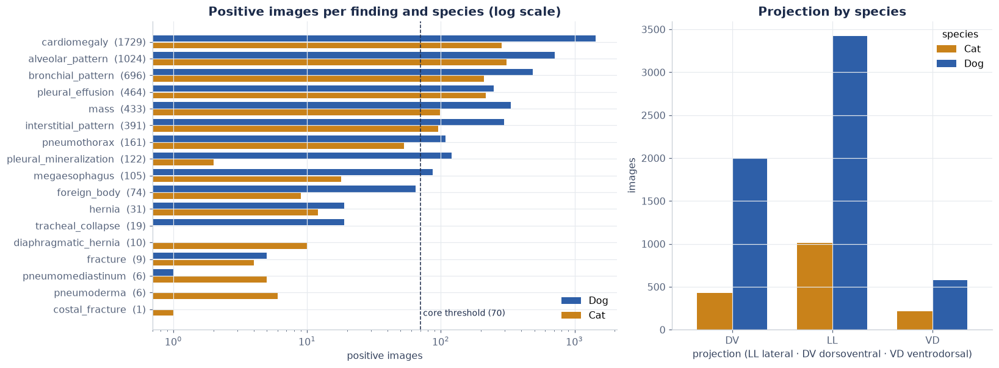

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), gridspec_kw={"width_ratios": [1.45, 1]})
order = lab.index.tolist()
ax = axes[0]
y = np.arange(len(order))
ax.barh(y - 0.2, lab.loc[order, "dogs +"], height=0.38, color=SPECIES_COLORS["Dog"], label="Dog")
ax.barh(y + 0.2, lab.loc[order, "cats +"], height=0.38, color=SPECIES_COLORS["Cat"], label="Cat")
ax.set_yticks(y, [f"{f}  ({lab.loc[f,'positive']})" for f in order]); ax.invert_yaxis(); ax.set_xscale("log")
ax.axvline(MIN_POS_CORE, color=NAVY, ls="--", lw=1); ax.text(MIN_POS_CORE * 1.05, len(order) - 0.6, "core threshold (70)", color=NAVY, fontsize=9)
ax.set(title="Positive images per finding and species (log scale)", xlabel="positive images")
ax.legend(loc="lower right")
ax = axes[1]
counts = Counter(df["species"]); proj = df.groupby(["projection", "species"]).size().unstack(fill_value=0)
proj.plot.bar(ax=ax, color=[SPECIES_COLORS[c] for c in proj.columns], width=0.7, rot=0)
ax.set(title="Projection by species", xlabel="projection (LL lateral · DV dorsoventral · VD ventrodorsal)", ylabel="images")
plt.tight_layout(); plt.show()

**What the chart shows.** The label distribution spans three orders of magnitude, from 1,700+ cardiomegaly images to a
single costal fracture. Cats are under-represented for every finding (≈ 22 % of images), so cat-specific estimates will
have wide uncertainty. Lateral views dominate, which matters because several findings (e.g. pneumothorax, megaesophagus)
look different on lateral and DV/VD views.

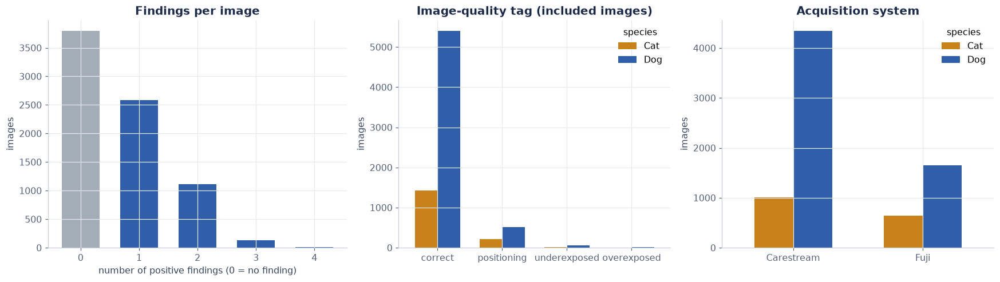

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
nf = df["n_findings"].clip(upper=5).value_counts().sort_index()
axes[0].bar([str(i) if i < 5 else "5+" for i in nf.index], nf.to_numpy(), color=[GREY] + [BLUE] * (len(nf) - 1), width=0.65)
axes[0].set(title="Findings per image", xlabel="number of positive findings (0 = no finding)", ylabel="images")
q = df.groupby(["quality", "species"]).size().unstack(fill_value=0).loc[lambda t: t.sum(axis=1).sort_values(ascending=False).index]
q.plot.bar(ax=axes[1], color=[SPECIES_COLORS[c] for c in q.columns], rot=0, width=0.7)
axes[1].set(title="Image-quality tag (included images)", xlabel="", ylabel="images")
sc = df.groupby(["scanner", "species"]).size().unstack(fill_value=0)
sc.plot.bar(ax=axes[2], color=[SPECIES_COLORS[c] for c in sc.columns], rot=0, width=0.6)
axes[2].set(title="Acquisition system", xlabel="", ylabel="images")
plt.tight_layout(); plt.show()

About half of the included images carry no finding, and multi-finding images are common (a single film can show
cardiomegaly, an alveolar pattern and pleural effusion together, a typical congestive heart-failure picture). Around 20 %
of included images carry a positioning or exposure flag; they stay in the study so the model sees real clinical
variability, and their performance is analysed separately.

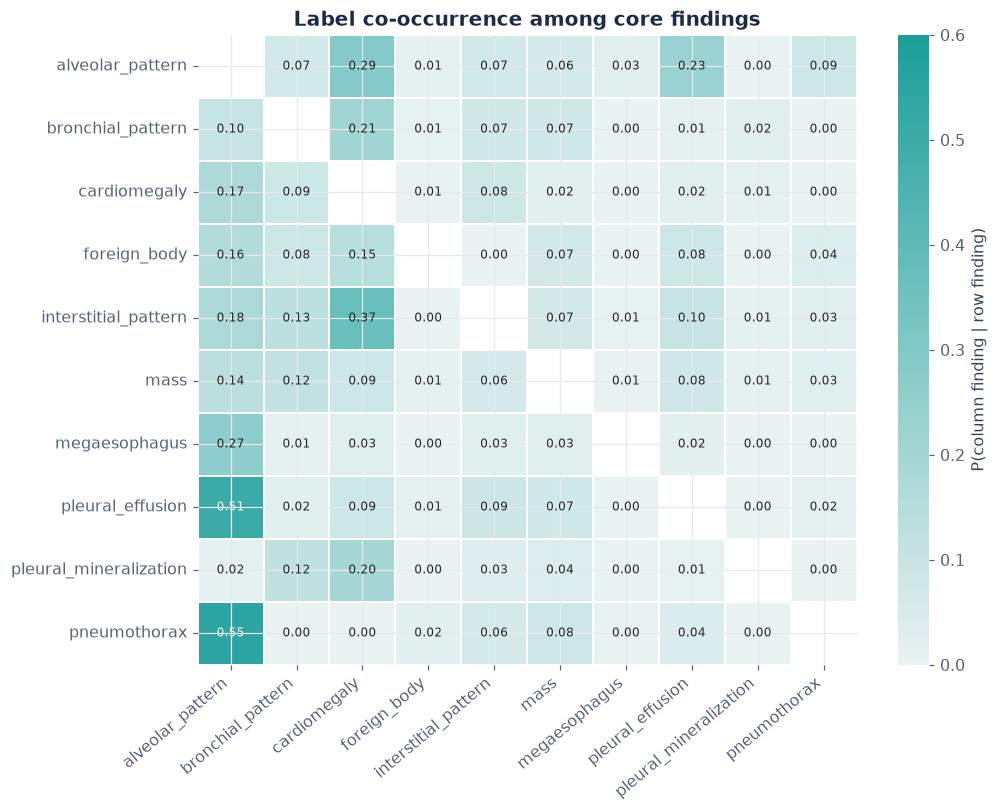

In [10]:
C = Y[:, [FINDINGS.index(f) for f in CORE]]
co = C.T @ C
cond = co / np.maximum(np.diag(co)[:, None], 1)   # P(column | row)
fig, ax = plt.subplots(figsize=(9.5, 7.5))
mask = np.eye(len(CORE), dtype=bool)
sns.heatmap(cond, mask=mask, cmap=sns.light_palette(TEAL, as_cmap=True), vmin=0, vmax=0.6, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, xticklabels=CORE, yticklabels=CORE, cbar_kws={"label": "P(column finding | row finding)"},
            linewidths=1, linecolor="white", ax=ax)
ax.set_title("Label co-occurrence among core findings"); ax.set_xlabel(""); ax.set_ylabel("")
plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

**Reading the co-occurrence map.** Each cell is the probability of the *column* finding given the *row* finding.
About half of the pleural-effusion and pneumothorax images also carry an alveolar pattern, and more than a third of
interstitial-pattern images also show cardiomegaly. Because of these correlations, a model can be "right for the wrong
reason" (predicting one finding because it sees a frequent companion). This is one reason the per-finding error
analysis in §13 matters.

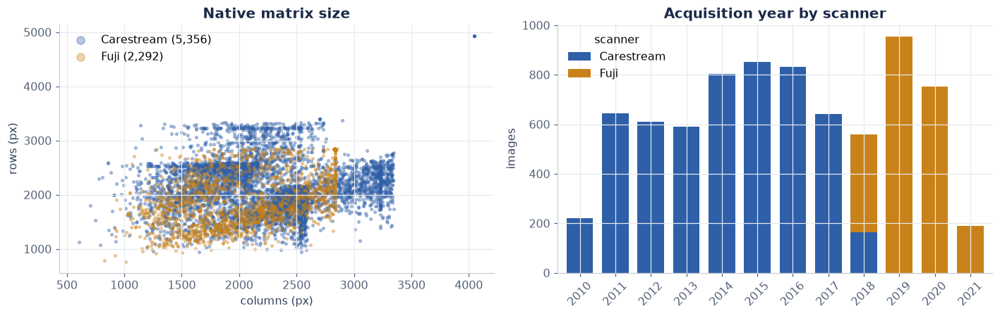

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
for sc_name, color in [("Carestream", BLUE), ("Fuji", AMBER)]:
    s = df[df.scanner == sc_name]
    ax[0].scatter(s["Columns"], s["Rows"], s=6, alpha=0.35, color=color, label=f"{sc_name} ({len(s):,})")
ax[0].set(title="Native matrix size", xlabel="columns (px)", ylabel="rows (px)"); ax[0].legend(markerscale=3)
yrs = df["StudyDate"].astype(str).str[:4]
yr = pd.crosstab(yrs, df["scanner"])
yr.plot.bar(ax=ax[1], stacked=True, color=[BLUE, AMBER], width=0.75, rot=45)
ax[1].set(title="Acquisition year by scanner", xlabel="", ylabel="images")
plt.tight_layout(); plt.show()

Native images range from roughly 1,000 to 3,200 pixels per side, with Fuji films clustering at 2,832 px. All images are
letterboxed to a 512-pixel cache and then resized to 384 px for training, so aspect ratio is preserved and no anatomy is
cropped away. The year chart shows the scanners were used in overlapping periods, which reduces (but does not remove)
the risk of a scanner↔era↔label confound.

## 4 · Visual Tour and DICOM Processing

### 4.1 · From DICOM to a model-ready image

**An everyday analogy.** Two cameras photograph the same scene, but one stores dark as 0 and the other stores dark as
16,383. Before comparing photos you must put both on the same scale and the same polarity. DICOM preprocessing does
exactly that:

1. **Modality LUT** — apply `RescaleSlope` / `RescaleIntercept` when present.
2. **Robust intensity window** — clip to the 0.5th and 99.5th percentiles and map to [0, 1]. This removes extreme pixels
   (collimator edges, burned-in markers) without hand-tuned windows.
3. **Photometric interpretation** — `MONOCHROME1` images are inverted, so bone is always bright.
4. **Letterbox** — resize the long side to 512 px (Lanczos) and pad to a square, preserving aspect ratio.
5. **Model input** — at training time the 512-px image is resized to 384 px, replicated to three channels for
   pretrained networks, and normalised with each model's own mean/std.

The same functions (copied verbatim) are used by `petai_xray_inference.py`, and §13 verifies the two produce identical
outputs.

In [12]:
# ---- shared preprocessing (identical copy lives in petai_xray_inference.py) ----
PREPROCESS_VERSION = "vxr-pre-1.0"
CACHE_SIZE = 512            # side of the square, letterboxed image stored in the cache
PCT_LOW, PCT_HIGH = 0.5, 99.5  # robust intensity window (percentiles of the body of the image)


def dicom_to_unit_float(ds):
    """DICOM dataset -> float32 image in [0, 1] where *bright = radiodense* (MONOCHROME2 convention).

    Steps: Modality LUT (slope/intercept) -> robust percentile window -> MONOCHROME1 inversion.
    The VOI window stored in VetXRay headers spans the full bit range (e.g. WC 8192 / WW 16384),
    so it carries no clinical windowing information; a data-driven percentile window is used instead.
    """
    from pydicom.pixels import apply_modality_lut

    arr = ds.pixel_array
    if arr.ndim == 3:  # colour or multi-frame: keep the first frame / luminance
        arr = arr[0] if arr.shape[-1] not in (3, 4) else arr[..., :3].mean(-1)
    arr = apply_modality_lut(arr, ds).astype(np.float32)
    img = window_percentile(arr)
    if str(getattr(ds, "PhotometricInterpretation", "MONOCHROME2")).upper() == "MONOCHROME1":
        img = 1.0 - img
    return img


def window_percentile(arr):
    """Clip to [P0.5, P99.5] (estimated on a 4x-subsampled grid for speed) and rescale to [0, 1]."""
    arr = np.nan_to_num(arr.astype(np.float32), nan=0.0, posinf=0.0, neginf=0.0)
    sample = arr[::4, ::4]
    lo, hi = np.percentile(sample, [PCT_LOW, PCT_HIGH])
    if not np.isfinite(lo) or not np.isfinite(hi) or hi - lo < 1e-6:
        lo, hi = float(arr.min()), float(arr.max()) + 1e-6
    return np.clip((arr - lo) / (hi - lo), 0.0, 1.0)


def letterbox_uint8(img, size=CACHE_SIZE):
    """Resize the long side to `size` (aspect ratio preserved, Lanczos), pad to a square, quantise to uint8."""
    from PIL import Image

    h, w = img.shape
    scale = size / max(h, w)
    nh, nw = max(1, round(h * scale)), max(1, round(w * scale))
    small = np.asarray(Image.fromarray(img.astype(np.float32)).resize((nw, nh), Image.Resampling.LANCZOS))
    out = np.zeros((size, size), dtype=np.float32)
    top, left = (size - nh) // 2, (size - nw) // 2
    out[top:top + nh, left:left + nw] = np.clip(small, 0.0, 1.0)
    return np.round(out * 255.0).astype(np.uint8)

_PRE = {}


def _precomputed_cache():
    """Lazy, memory-mapped access to the uploaded cache (images_512.npy + cache_index.csv)."""
    if not _PRE:
        if not ((CACHE_DIR / "images_512.npy").exists() and (CACHE_DIR / "cache_index.csv").exists()):
            raise FileNotFoundError(f"CACHE_ONLY mode needs images_512.npy and cache_index.csv in {CACHE_DIR}")
        _idx = pd.read_csv(CACHE_DIR / "cache_index.csv")
        _PRE.update(images=np.load(CACHE_DIR / "images_512.npy", mmap_mode="r"), row_of=dict(zip(_idx.FileName, _idx.row)))
    return _PRE["images"], _PRE["row_of"]


def load_cached_style(name):
    """DICOM file name -> uint8 512x512 letterboxed image (the cache representation)."""
    if CACHE_ONLY:   # no DICOMs available: the cache holds exactly this representation
        imgs, row_of = _precomputed_cache()
        return np.array(imgs[int(row_of[name])])
    return letterbox_uint8(dicom_to_unit_float(src.read(name)))

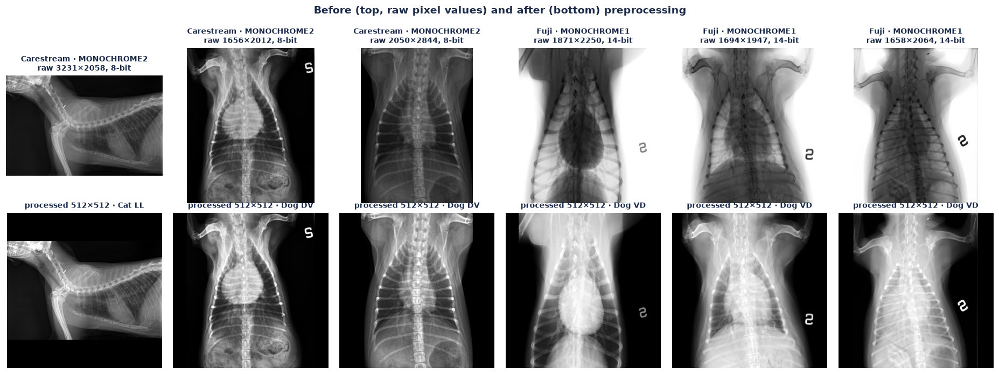

In [13]:
rng = np.random.default_rng(SEED)
demo = pd.concat([df[(df.scanner == s)].sample(3, random_state=SEED) for s in ["Carestream", "Fuji"]])
if CACHE_ONLY:   # raw DICOMs are not available here: show the processed cache images with their native header facts
    fig, axes = plt.subplots(1, 6, figsize=(17, 3.6))
    for k, (_, r) in enumerate(demo.iterrows()):
        axes[k].imshow(load_cached_style(r.FileName), cmap="gray", vmin=0, vmax=255); axes[k].axis("off")
        axes[k].set_title(f"{r.scanner} · {r.PhotometricInterpretation}\nnative {int(r.Columns)}×{int(r.Rows)}, {int(r.BitsStored)}-bit · {r.species} {r.projection}", fontsize=8.5)
    fig.suptitle("Processed 512×512 cache images (raw DICOMs are not part of this environment)", color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()
else:
    fig, axes = plt.subplots(2, 6, figsize=(17, 6.4))
    for k, (_, r) in enumerate(demo.iterrows()):
        ds = src.read(r.FileName)
        raw = ds.pixel_array.astype(np.float32)
        proc = letterbox_uint8(dicom_to_unit_float(ds))
        axes[0, k].imshow(raw, cmap="gray"); axes[1, k].imshow(proc, cmap="gray", vmin=0, vmax=255)
        axes[0, k].set_title(f"{r.scanner} · {ds.PhotometricInterpretation}\nraw {raw.shape[1]}×{raw.shape[0]}, {int(ds.BitsStored)}-bit", fontsize=9)
        axes[1, k].set_title(f"processed 512×512 · {r.species} {r.projection}", fontsize=9)
    for a in axes.flat: a.axis("off")
    fig.suptitle("Before (top, raw pixel values) and after (bottom) preprocessing", color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()

**Interpretation.** Raw Fuji images (`MONOCHROME1`) display inverted: bones appear dark. After processing, both systems
share the same polarity and a comparable contrast range. Some films are acquired rotated by 90°; this is a genuine
property of the data, kept as is (the model must cope with it, as a radiologist would).

### 4.2 · Building the image cache

Decoding a 16 MB DICOM takes ~0.2 s. Doing that every epoch for seven models would waste hours, so each included image
is decoded **once** and stored as a 512×512 `uint8` array in a single memory-mapped file (`images_512.npy`, ~2 GB) in
`WORK_DIR`, outside the project folder. Training then reads only the rows it needs from disk (lazy loading), which also
works with `num_workers=0`, the safe DataLoader setting for Jupyter on Windows.

On Kaggle, the cache can be attached as a dataset (`cache_index.csv` + `images_512.npy`), so the notebook runs without
the 41 GB of DICOMs.

In [14]:
def build_cache(names, out_dir, tag):
    out_dir = Path(out_dir); out_dir.mkdir(parents=True, exist_ok=True)
    sfx = "" if tag == "full" else f"_{tag}"   # the full cache keeps the plain names that the Kaggle mode expects
    npy, idx, done = out_dir / f"images_512{sfx}.npy", out_dir / f"cache_index{sfx}.csv", out_dir / f"cache{sfx}.done.json"
    if done.exists() and json.loads(done.read_text()).get("version") == PREPROCESS_VERSION:
        index = pd.read_csv(idx)
        if set(index.FileName) >= set(names):
            return np.load(npy, mmap_mode="r"), dict(zip(index.FileName, index.row))
    names = list(names)
    arr = np.lib.format.open_memmap(npy, mode="w+", dtype=np.uint8, shape=(len(names), CACHE_SIZE, CACHE_SIZE))
    def work(i):
        arr[i] = load_cached_style(names[i]); return i
    t0, n_done = time.time(), 0
    with ThreadPoolExecutor(max_workers=min(8, os.cpu_count() or 4)) as ex:
        for _ in ex.map(work, range(len(names))):
            n_done += 1
            if n_done % 500 == 0 or n_done == len(names):
                print(f"  cached {n_done:,}/{len(names):,}  ({time.time()-t0:.0f}s)")
    arr.flush(); del arr
    pd.DataFrame({"FileName": names, "row": range(len(names))}).to_csv(idx, index=False)
    done.write_text(json.dumps({"version": PREPROCESS_VERSION, "n": len(names), "size": CACHE_SIZE}))
    return np.load(npy, mmap_mode="r"), {n: i for i, n in enumerate(names)}

## 5 · Animal-Level, Label-Stratified Split

**Requirements.** (1) every group (animal) belongs to exactly one partition; (2) each finding, each species and each
scanner keeps roughly the same share in train, validation and test; (3) the split is deterministic.

Standard `GroupShuffleSplit` satisfies (1) but ignores label balance, which is fatal for findings with 10–20 animals.
The function below is a group-level version of *iterative stratification* (Sechidis et al., 2011): it repeatedly
takes the label with the fewest unassigned positives and places every animal carrying it into the partition that
currently lacks that label the most.

Why 70 / 15 / 15? With ~2,500 animal groups, 15 % gives each of the 10 core findings at least ~10 positive test images,
while keeping 70 % for training. Rare findings with fewer than ~7 animals cannot appear in all three partitions; this
is reported, not hidden.

In [15]:
def stratified_group_split(groups, strat, fracs=SPLIT_FRACS, seed=SEED):
    """Group-level iterative stratification (Sechidis et al., 2011).
    groups: (N,) animal-group id per image; strat: (N, K) binary stratification targets.
    Repeatedly takes the label with the fewest *unassigned* positives and places every group carrying it into the
    partition with the largest remaining quota for that label (ties -> largest remaining image quota)."""
    rng = np.random.default_rng(seed)
    g_ids, g_inv = np.unique(groups, return_inverse=True)
    G = np.zeros((len(g_ids), strat.shape[1])); np.add.at(G, g_inv, strat)
    g_size = np.bincount(g_inv).astype(float); fr = np.asarray(fracs, float)
    need, need_n = np.outer(fr, G.sum(0)), fr * g_size.sum()
    unassigned, assign = np.ones(len(g_ids), bool), np.full(len(g_ids), -1)
    perm = rng.permutation(len(g_ids))
    def place(g, s):
        assign[g] = s; need[s] -= G[g]; need_n[s] -= g_size[g]; unassigned[g] = False
    while unassigned.any():
        remaining = G[unassigned].sum(0)
        if not (remaining > 0).any():                       # groups without any target: fill by image quota
            for g in perm[unassigned[perm]]:
                place(g, int(np.argmax(need_n + 1e-9 * rng.random(3))))
            break
        l = int(np.argmin(np.where(remaining > 0, remaining, np.inf)))
        for g in perm[unassigned[perm] & (G[perm, l] > 0)]:
            best = np.flatnonzero(np.isclose(need[:, l], need[:, l].max()))
            place(g, int(best[np.argmax(need_n[best])]) if len(best) > 1 else int(best[0]))
    return np.array(["train", "val", "test"])[assign[g_inv]]

if CACHE_ONLY:   # split and group ids were restored from the metadata CSV (section 3.3)
    assert df.groupby("group")["split"].nunique().max() == 1, "an animal group spans two partitions"
else:
    strat = np.concatenate([Y, df[["no_finding"]].values.astype(float),
                            pd.get_dummies(df["species"]).values.astype(float),
                            pd.get_dummies(df["scanner"]).values.astype(float)], axis=1)
    df["split"] = stratified_group_split(df["group"].values, strat)

    # -- leakage guards: these must hold, otherwise the notebook stops here
    assert df.groupby("group")["split"].nunique().max() == 1, "an animal group spans two partitions"
    for key in ["PatientID"]:
        assert df.groupby(key)["split"].nunique().max() == 1, f"{key} spans two partitions"
    print("leakage checks passed: no animal group or PatientID crosses partitions")

    # -- anonymous, DICOM-free metadata for the Kaggle dataset: no PatientName, no PatientID, shuffled integer group ids.
    #    Relabelling happens AFTER the split, so the partition is unchanged and both modes use identical ids.
    df["group"] = np.random.default_rng(SEED).permutation(df["group"].nunique())[pd.factorize(df["group"], sort=True)[0]]
    META_EXPORT_COLS = ["FileName", "species", "breed", "projection", "quality", "tags", "scanner", "PhotometricInterpretation",
                        "BitsStored", "Rows", "Columns", "StudyDate", "group", "split"]
    _exp = df[META_EXPORT_COLS].copy()
    _exp["tags"] = df["tags"].apply("|".join)
    (WORK_DIR / "kaggle_dataset").mkdir(parents=True, exist_ok=True)
    _exp.to_csv(WORK_DIR / "kaggle_dataset" / "vetxray_metadata.csv", index=False)
    print(f"anonymous metadata exported: {len(_exp):,} rows -> {WORK_DIR / 'kaggle_dataset' / 'vetxray_metadata.csv'}")

sizes = df["split"].value_counts().reindex(["train", "val", "test"])
display(pd.DataFrame({"images": sizes, "animal groups": df.groupby("split")["group"].nunique().reindex(sizes.index),
                      "share": (sizes / len(df)).map("{:.1%}".format)}))

leakage checks passed: no animal group or PatientID crosses partitions
anonymous metadata exported: 7,648 rows -> G:\VetXRay_cache\kaggle_dataset\vetxray_metadata.csv


,images,animal groups,share
split,,,
train,5353,1776,70.0%
val,1139,354,14.9%
test,1156,375,15.1%


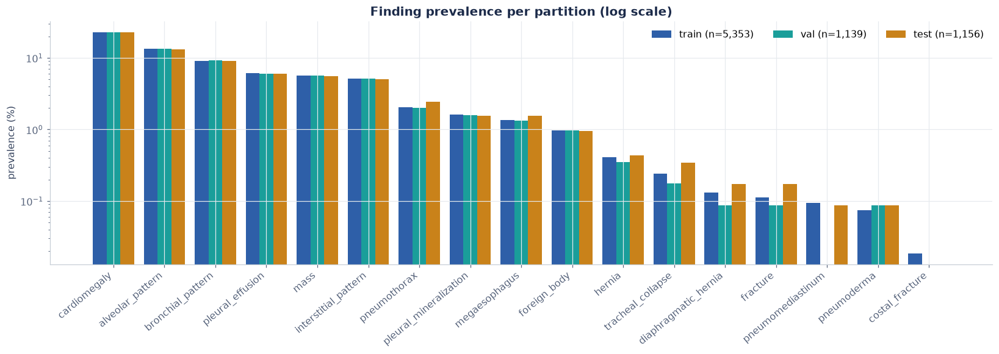

,cardiomegaly,alveolar_pattern,bronchial_pattern,pleural_effusion,mass,interstitial_pattern,pneumothorax,pleural_mineralization,megaesophagus,foreign_body,hernia,tracheal_collapse,diaphragmatic_hernia,fracture,pneumomediastinum,pneumoderma,costal_fracture
train,1208,718,486,325,304,275,110,86,72,52,22,13,7,6,5,4,1
val,259,153,106,69,65,58,23,18,15,11,4,2,1,1,0,1,0
test,262,153,104,70,64,58,28,18,18,11,5,4,2,2,1,1,0


In [16]:
fig, ax = plt.subplots(figsize=(15, 5.4))
order = lab.index.tolist()
x = np.arange(len(order)); w = 0.27
for k, s in enumerate(["train", "val", "test"]):
    m = (df["split"] == s).values
    prev = Y[m][:, [FINDINGS.index(f) for f in order]].mean(0) * 100
    ax.bar(x + (k - 1) * w, prev, width=w, color=SPLIT_COLORS[s], label=f"{s} (n={m.sum():,})")
ax.set_xticks(x, order, rotation=40, ha="right"); ax.set_yscale("log")
ax.set(title="Finding prevalence per partition (log scale)", ylabel="prevalence (%)")
ax.legend(ncol=3, loc="upper right")
plt.tight_layout(); plt.show()
cnt = pd.DataFrame({s: Y[(df.split == s).values].sum(0).astype(int) for s in ["train", "val", "test"]}, index=FINDINGS)
display(cnt.loc[order].T.style.background_gradient(cmap=sns.light_palette(TEAL, as_cmap=True), axis=None))

**Interpretation.** Bars of the three colours have almost equal height for every core finding, so validation and test
are representative of training. For the rare findings the count table shows the hard limit of the dataset: some test
folds contain only 0–2 positives. Any metric on those findings would be anecdotal, which is why they are excluded from
the primary score.

### 5.1 · Sample gallery

Twelve radiographs drawn from the training partition with their true labels, species, view and quality tag.

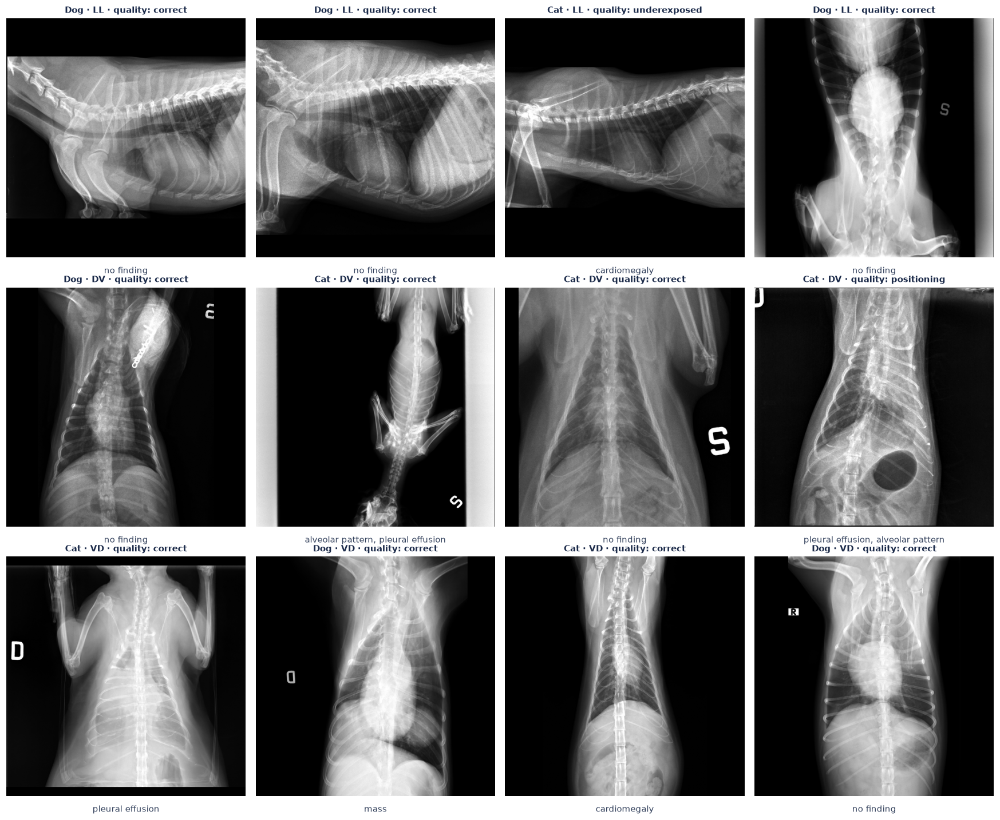

In [17]:
def short(tags):
    t = [x for x in tags if x in FINDINGS]
    return ", ".join(x.replace("_", " ") for x in t) if t else "no finding"

gal = pd.concat([df[(df.split == "train") & (df.projection == p)].sample(4, random_state=SEED) for p in ["LL", "DV", "VD"]])
fig, axes = plt.subplots(3, 4, figsize=(16, 13))
for a, (_, r) in zip(axes.flat, gal.iterrows()):
    a.imshow(load_cached_style(r.FileName), cmap="gray")
    a.set_title(f"{r.species} · {r.projection} · quality: {r.quality}", fontsize=10, color=NAVY, fontweight="bold")
    a.text(0.5, -0.04, short(r.tags), transform=a.transAxes, ha="center", va="top", fontsize=9.5, color="#33415C", wrap=True)
    a.axis("off")
plt.tight_layout(); plt.show()

### 5.2 · Pathology gallery

Up to three positive examples per finding. Each image may carry other findings too (listed under it): appearing in the
"mass" row does not mean the image shows *only* a mass.

In [18]:
def pathology_gallery(findings, per=3):
    fig, axes = plt.subplots(len(findings), per, figsize=(per * 3.6, len(findings) * 3.9))
    axes = np.atleast_2d(axes)
    for i, f in enumerate(findings):
        cand = df[(Y[:, FINDINGS.index(f)] > 0) & (df.split == "train")]
        if len(cand) < per:   # rare finding: allow any partition, display only
            cand = df[Y[:, FINDINGS.index(f)] > 0]
        pick = cand.sample(min(per, len(cand)), random_state=SEED) if len(cand) else cand
        for j in range(per):
            a = axes[i, j]; a.axis("off")
            if j < len(pick):
                r = pick.iloc[j]
                a.imshow(load_cached_style(r.FileName), cmap="gray")
                others = [x.replace("_", " ") for x in r.tags if x in FINDINGS and x != f]
                a.set_title(f"{r.species} · {r.projection}" + (f"\n+ {', '.join(others)}" if others else ""), fontsize=8.5)
        axes[i, 0].text(-0.08, 0.5, f.replace("_", "\n"), transform=axes[i, 0].transAxes, ha="right", va="center",
                        fontsize=11, fontweight="bold", color=NAVY)
    plt.tight_layout(); plt.show()

display(Markdown("\n".join(f"* **{f}** ({pos[f]} images): {FINDING_INFO[f]}" for f in lab.index)))

* **cardiomegaly** (1729 images): Enlarged cardiac silhouette relative to the thorax (e.g. vertebral heart score above breed reference).
* **alveolar_pattern** (1024 images): Air spaces filled with fluid/cells: fluffy opacities, air bronchograms (pneumonia, oedema, haemorrhage).
* **bronchial_pattern** (696 images): Thickened bronchial walls: 'donuts' and 'tram lines' (chronic bronchitis, feline asthma).
* **pleural_effusion** (464 images): Fluid in the pleural space: interlobar fissures, rounded lung margins, effaced heart.
* **mass** (433 images): Focal soft-tissue opacity: pulmonary or mediastinal mass, nodule(s).
* **interstitial_pattern** (391 images): Increased hazy/reticular or nodular lung opacity that does not efface vessels.
* **pneumothorax** (161 images): Free air in the pleural space; heart elevated from the sternum on lateral views.
* **pleural_mineralization** (122 images): Mineral opacities of the pleura (often incidental in older dogs).
* **megaesophagus** (105 images): Dilated oesophagus visible as a gas- or fluid-filled tube in the dorsal thorax.
* **foreign_body** (74 images): Radiopaque object in airway, oesophagus or thorax.
* **hernia** (31 images): Herniation other than diaphragmatic (e.g. peritoneopericardial, hiatal).
* **tracheal_collapse** (19 images): Dynamic dorsoventral narrowing of the trachea (toy breeds).
* **diaphragmatic_hernia** (10 images): Abdominal organs displaced into the thorax through a diaphragmatic defect.
* **fracture** (9 images): Fracture of a thoracic skeletal structure other than ribs (e.g. vertebra, sternum).
* **pneumomediastinum** (6 images): Free gas in the mediastinum outlining vessels and the oesophagus.
* **pneumoderma** (6 images): Gas within the subcutaneous tissues.
* **costal_fracture** (1 images): Fracture of a rib.

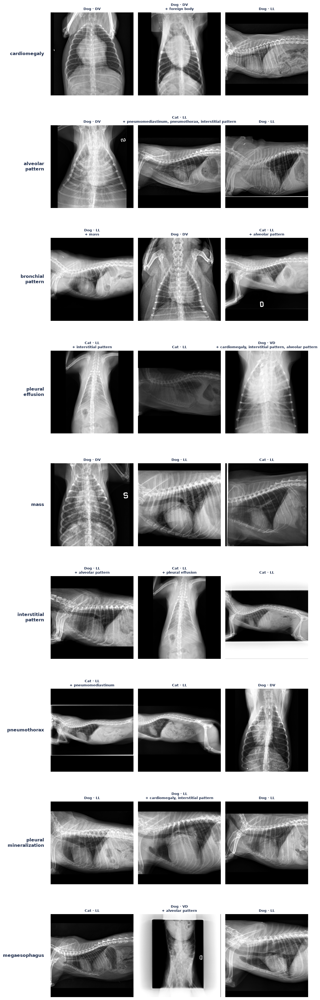

In [19]:
pathology_gallery(lab.index[:9].tolist())

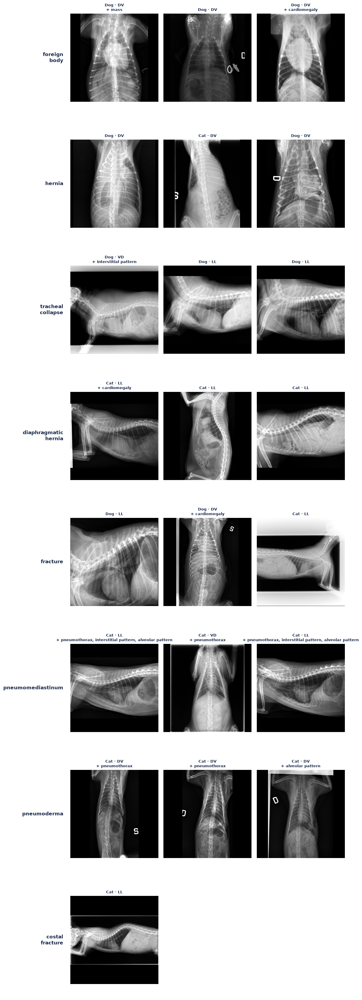

In [20]:
pathology_gallery(lab.index[9:].tolist())

### 5.3 · Cache construction

In SMOKE mode only a small stratified subset is cached. In FULL mode all included images are cached once
(roughly 10–20 minutes on a laptop, mostly ZIP decompression).

In [21]:
if RUN_MODE == "SMOKE":
    parts = []
    for s, n in zip(["train", "val", "test"], [SMOKE_N // 2, SMOKE_N // 4, SMOKE_N // 4]):
        sub = df[df.split == s]
        # make sure several findings are represented even in the tiny subset
        pick = sub[sub.n_findings > 0].sample(n // 2, random_state=SEED)
        parts.append(pd.concat([pick, sub.drop(pick.index).sample(n - len(pick), random_state=SEED)]))
    work = pd.concat(parts)
else:
    work = df
work = work.copy()

if CACHE_ONLY or PRECOMPUTED_CACHE:   # Kaggle: use the uploaded cache (images_512.npy + cache_index.csv)
    images, row_of = _precomputed_cache()
else:
    images, row_of = build_cache(sorted(work.FileName), CACHE_DIR, "smoke" if RUN_MODE == "SMOKE" else "full")
work["row"] = work.FileName.map(row_of)
assert work["row"].notna().all()
Y_work = np.array([[f in t for f in FINDINGS] for t in work["tags"]], dtype=np.float32)
print(f"cache: {images.shape} uint8 | working set: {len(work):,} images "
      f"({', '.join(f'{s} {int((work.split==s).sum())}' for s in ['train','val','test'])})")

cache: (7648, 512, 512) uint8 | working set: 7,648 images (train 5353, val 1139, test 1156)


## 6 · Training Pipeline

### 6.1 · Concepts in one minute

* **Sigmoid vs softmax.** Softmax makes outputs compete ("pick one disease"). Sigmoid gives each finding its own
  independent probability, which is what a multi-finding radiograph needs.
* **`BCEWithLogitsLoss`.** Binary cross-entropy applied to each of the 17 outputs, computed from raw logits for numerical
  stability. A per-label mask multiplies the loss so that unknown labels would contribute nothing.
* **Class imbalance.** Following the `ml-researcher` guidance, the data are not resampled. Imbalance is handled by
  (a) a *ranking* metric (PR-AUC) that is insensitive to the decision threshold, (b) per-finding thresholds chosen on
  validation, and (c) an optional, capped `pos_weight` that Optuna may switch on.
* **Two-stage fine-tuning.** Stage 1 trains only the new head on a frozen backbone (feature extraction), so the random
  head cannot destroy pretrained features. Stage 2 unfreezes part of the backbone with a learning rate ~10× smaller
  than the head's.
* **Mixed precision** (`torch.autocast` + `GradScaler`) halves activation memory on the RTX 4060.
* **Gradient accumulation** reaches an effective batch of 32 while only 16 images sit on the GPU.
* **Early stopping** keeps the epoch with the best validation macro PR-AUC (core findings) and stops after `patience`
  epochs without improvement.

### 6.2 · Data loading and on-GPU augmentation

Augmentations are deliberately mild and anatomically plausible: rotation ±7°, scale ±7 %, shift ±4 %, brightness and
contrast ±10 %, gamma 0.9–1.1. **No flips**: on DV/VD views the cardiac apex lies to the left, and flipping would
create anatomy that does not exist. (The original VetXRay papers used flips; this choice is a deliberate difference.)
Augmentation runs on the GPU as a batched affine warp, so it costs almost nothing even with `num_workers=0`.

In [22]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
NUM_WORKERS = 0 if os.name == "nt" else 2
torch.backends.cudnn.benchmark = True
print(f"device: {DEVICE} | AMP: {AMP} | DataLoader workers: {NUM_WORKERS}")

class CachedXrays(Dataset):
    def __init__(self, frame, labels):
        self.rows = frame["row"].to_numpy().astype(int)
        self.y = torch.from_numpy(labels.astype(np.float32))
        self.mask = torch.ones_like(self.y)          # 1 = label known (all labels in this release)
    def __len__(self):
        return len(self.rows)
    def __getitem__(self, i):
        img = torch.from_numpy(np.ascontiguousarray(images[self.rows[i]]))[None]   # (1, 512, 512) uint8
        return img, self.y[i], self.mask[i]

def make_loader(split, batch_size, shuffle):
    m = (work["split"] == split).values
    return DataLoader(CachedXrays(work[m], Y_work[m]), batch_size=batch_size, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=AMP, drop_last=False,
                      generator=torch.Generator().manual_seed(SEED))

def gpu_augment(x):
    """x: (B,1,H,W) float in [0,1] on device -> mildly augmented copy."""
    B = x.shape[0]; dev = x.device
    ang = (torch.rand(B, device=dev) * 2 - 1) * math.radians(7)
    scl = 1 + (torch.rand(B, device=dev) * 2 - 1) * 0.07
    tx, ty = [(torch.rand(B, device=dev) * 2 - 1) * 0.08 for _ in range(2)]   # 0.08 in [-1,1] coords = 4 %
    cos, sin = torch.cos(ang) / scl, torch.sin(ang) / scl
    theta = torch.stack([torch.stack([cos, -sin, tx], 1), torch.stack([sin, cos, ty], 1)], 1)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    c = 1 + (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.10
    b = (torch.rand(B, 1, 1, 1, device=dev) * 2 - 1) * 0.10
    g = 0.9 + torch.rand(B, 1, 1, 1, device=dev) * 0.2
    return ((x.clamp(0, 1) ** g) * c + b).clamp(0, 1)

def prepare(x_uint8, spec, train):
    """uint8 cache batch -> normalised model input (B, C, S, S). Identical logic in petai_xray_inference.py."""
    x = x_uint8.to(DEVICE, non_blocking=True).float() / 255.0
    if train:
        x = gpu_augment(x)
    x = F.interpolate(x, size=(spec.input_size, spec.input_size), mode="bilinear", align_corners=False, antialias=True)
    if spec.in_chans == 3:
        x = x.expand(-1, 3, -1, -1)
    mean = torch.tensor(spec.mean, device=DEVICE).view(1, -1, 1, 1)
    std = torch.tensor(spec.std, device=DEVICE).view(1, -1, 1, 1)
    return (x - mean) / std

device: cuda | AMP: True | DataLoader workers: 0


### 6.3 · Augmentation preview

Eight random augmentations of the same radiograph, produced by the exact function used during training.

<temp>\ipykernel_10172\1129715398.py:1: UserWarning: The given NumPy array is not writable, and PyTorch does not support non-writable tensors. This means writing to this tensor will result in undefined behavior. You may want to copy the array to protect its data or make it writable before converting it to a tensor. This type of warning will be suppressed for the rest of this program. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\pytorch\torch\csrc\utils\tensor_numpy.cpp:219.)
  _x = torch.from_numpy(np.ascontiguousarray(images[int(work.iloc[0]["row"])]))[None, None].repeat(8, 1, 1, 1)


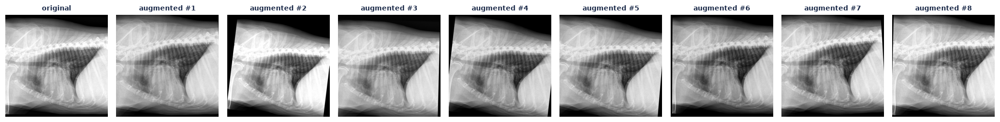

In [23]:
_x = torch.from_numpy(np.ascontiguousarray(images[int(work.iloc[0]["row"])]))[None, None].repeat(8, 1, 1, 1)
_aug = gpu_augment(_x.to(DEVICE).float() / 255).cpu().numpy()
fig, axes = plt.subplots(1, 9, figsize=(19, 2.6))
axes[0].imshow(_x[0, 0], cmap="gray"); axes[0].set_title("original", fontsize=9)
for k in range(8):
    axes[k + 1].imshow(_aug[k, 0], cmap="gray", vmin=0, vmax=1); axes[k + 1].set_title(f"augmented #{k+1}", fontsize=9)
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

### 6.4 · Metrics

**Why PR-AUC?** Imagine 1,000 films with 20 pneumothoraces. A model that ranks them poorly can still reach a high ROC-AUC
because the 980 negatives dominate the false-positive rate. Precision-recall AUC (average precision, AP) asks instead:
*among the films the model flags, how many are truly positive?* Its chance level equals the prevalence, so it exposes
weak performance on rare findings. ROC-AUC is reported alongside it.

Thresholds are chosen **per finding on the validation set** by maximising F1, then frozen and applied unchanged to the
test set. Undefined metrics (no positives in a split) are reported as `NaN`, never as zero.

In [24]:
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve, roc_curve, brier_score_loss

def per_label_metrics(y, p, thr):
    rows = []
    for j, f in enumerate(FINDINGS):
        yt, pp = y[:, j], p[:, j]
        npos = int(yt.sum()); defined = 0 < npos < len(yt)
        pred = pp >= thr[j]
        tp, fp, fn, tn = [int(v) for v in ((pred & (yt == 1)).sum(), (pred & (yt == 0)).sum(), (~pred & (yt == 1)).sum(), (~pred & (yt == 0)).sum())]
        prec = tp / (tp + fp) if tp + fp else np.nan
        rec = tp / (tp + fn) if tp + fn else np.nan
        rows.append({"finding": f, "tier": "core" if f in CORE else "rare", "n_pos": npos,
                     "PR-AUC": average_precision_score(yt, pp) if defined else np.nan,
                     "ROC-AUC": roc_auc_score(yt, pp) if defined else np.nan,
                     "threshold": thr[j], "precision": prec, "sensitivity": rec,
                     "specificity": tn / (tn + fp) if tn + fp else np.nan,
                     "F1": (2 * tp / (2 * tp + fp + fn)) if (2 * tp + fp + fn) else np.nan,
                     "TP": tp, "FP": fp, "FN": fn, "TN": tn})
    return pd.DataFrame(rows).set_index("finding")

def summary_metrics(y, p, thr=None):
    thr = np.full(len(FINDINGS), 0.5) if thr is None else np.asarray(thr)
    t = per_label_metrics(y, p, thr)
    core = t.loc[CORE]
    pred = p >= thr[None, :]
    tp, fp, fn = (pred & (y == 1)).sum(), (pred & (y == 0)).sum(), (~pred & (y == 1)).sum()
    return {"macro_PR_AUC_core": core["PR-AUC"].mean(), "macro_ROC_AUC_core": core["ROC-AUC"].mean(),
            "macro_F1_core": core["F1"].mean(), "macro_PR_AUC_all_defined": t["PR-AUC"].mean(),
            "micro_PR_AUC": average_precision_score(y.ravel(), p.ravel()) if y.sum() else np.nan,
            "micro_F1": 2 * tp / (2 * tp + fp + fn) if (2 * tp + fp + fn) else np.nan,
            "macro_sensitivity_core": core["sensitivity"].mean(), "macro_specificity_core": core["specificity"].mean(),
            "brier_core": float(np.mean([brier_score_loss(y[:, FINDINGS.index(f)], p[:, FINDINGS.index(f)]) for f in CORE]))}

def fit_thresholds(y, p):
    """Per-finding threshold maximising F1 on validation; 0.5 when the finding has no validation positives."""
    thr = np.full(len(FINDINGS), 0.5)
    for j in range(len(FINDINGS)):
        if 0 < y[:, j].sum() < len(y):
            pr, rc, th = precision_recall_curve(y[:, j], p[:, j])
            f1 = 2 * pr[:-1] * rc[:-1] / np.maximum(pr[:-1] + rc[:-1], 1e-9)
            thr[j] = float(th[np.nanargmax(f1)])
    return thr

def group_bootstrap_ci(y, p, groups, metric_fn, n=1000, seed=SEED):
    """95 % CI that resamples whole animals (not images), respecting within-animal correlation."""
    rng = np.random.default_rng(seed); ug = np.unique(groups)
    pos = {g: np.flatnonzero(groups == g) for g in ug}
    vals = []
    for _ in range(n):
        idx = np.concatenate([pos[g] for g in rng.choice(ug, len(ug), replace=True)])
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            vals.append(metric_fn(y[idx], p[idx]))
    return np.nanpercentile(vals, [2.5, 97.5])

def macro_ap_core(y, p):
    if not np.isfinite(p).all():      # diverged model (NaN/inf probabilities): no valid score
        return np.nan
    v = [average_precision_score(y[:, FINDINGS.index(f)], p[:, FINDINGS.index(f)]) for f in CORE if 0 < y[:, FINDINGS.index(f)].sum() < len(y)]
    return float(np.mean(v)) if v else np.nan

### 6.5 · Model factory

Each model is described by a `ModelSpec`: how to build it, its input normalisation, which parameters form the "head",
and an ordered list of backbone blocks used for partial unfreezing (the last *k* blocks are unfrozen in stage 2).

In [25]:
from dataclasses import dataclass, field

@dataclass
class ModelSpec:
    name: str
    family: str
    builder: callable
    input_size: int = TRAIN_SIZE
    in_chans: int = 3
    mean: tuple = (0.485, 0.456, 0.406)
    std: tuple = (0.229, 0.224, 0.225)
    pretrained: bool = True
    petai_candidate: bool = False
    source: str = ""
    lr_head: float = 1e-3
    lr_ratio: float = 0.1          # backbone lr = lr_head * lr_ratio
    unfreeze_frac: float = 1.0     # fraction of backbone blocks unfrozen in stage 2
    batch_size: int = 16
    accum: int = 2
    grad_ckpt: bool = False

class Classifier(nn.Module):
    """backbone -> (dropout) -> Linear(17). `blocks` lists backbone modules from input to output."""
    def __init__(self, backbone, feat_dim, blocks, drop=0.2, forward_fn=None):
        super().__init__()
        self.backbone, self.blocks = backbone, blocks
        self.drop = nn.Dropout(drop)
        self.head = nn.Linear(feat_dim, len(FINDINGS))
        self._fwd = forward_fn
    def features(self, x):
        return self._fwd(self.backbone, x) if self._fwd else self.backbone(x)
    def forward(self, x):
        return self.head(self.drop(self.features(x)))

# ---------------------------------------------------------------- Model A: custom VGG-style CNN
def conv_bn(cin, cout, k=3, s=1):
    return nn.Sequential(nn.Conv2d(cin, cout, k, s, k // 2, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True))

class CustomCNN(nn.Module):
    """Five blocks of [conv-BN-ReLU] x2 + max-pool. 384 -> 12 px feature map, then global average pooling."""
    widths = (32, 64, 128, 256, 384)
    def __init__(self):
        super().__init__()
        layers, cin = [], 1
        for w in self.widths:
            layers.append(nn.Sequential(conv_bn(cin, w), conv_bn(w, w), nn.MaxPool2d(2)))
            cin = w
        self.stages = nn.Sequential(*layers)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = cin
    def forward(self, x):
        return self.pool(self.stages(x)).flatten(1)

# ---------------------------------------------------------------- Model B: custom residual CNN with squeeze-and-excitation
class SE(nn.Module):
    def __init__(self, c, r=8):
        super().__init__()
        self.fc = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Conv2d(c, c // r, 1), nn.ReLU(inplace=True), nn.Conv2d(c // r, c, 1), nn.Sigmoid())
    def forward(self, x):
        return x * self.fc(x)

class ResBlock(nn.Module):
    def __init__(self, cin, cout, stride):
        super().__init__()
        self.body = nn.Sequential(conv_bn(cin, cout, 3, stride), nn.Conv2d(cout, cout, 3, 1, 1, bias=False), nn.BatchNorm2d(cout), SE(cout))
        self.skip = nn.Identity() if (cin == cout and stride == 1) else nn.Sequential(nn.Conv2d(cin, cout, 1, stride, bias=False), nn.BatchNorm2d(cout))
    def forward(self, x):
        return F.relu(self.body(x) + self.skip(x), inplace=True)

class CustomResNet(nn.Module):
    """Stem (7x7, s2) + max-pool, then 4 stages x 2 residual blocks with SE attention: 384 -> 12 px."""
    widths = (48, 96, 192, 384)
    def __init__(self):
        super().__init__()
        self.stem = nn.Sequential(conv_bn(1, 32, 7, 2), nn.MaxPool2d(3, 2, 1))
        stages, cin = [], 32
        for i, w in enumerate(self.widths):
            stages.append(nn.Sequential(ResBlock(cin, w, 1 if i == 0 else 2), ResBlock(w, w, 1)))
            cin = w
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = cin
    def forward(self, x):
        return self.pool(self.stages(self.stem(x))).flatten(1)

def build_custom_cnn(spec, drop=0.3):
    b = CustomCNN(); return Classifier(b, b.out_dim, list(b.stages), drop)

def build_custom_resnet(spec, drop=0.3):
    b = CustomResNet(); return Classifier(b, b.out_dim, [b.stem] + list(b.stages), drop)

# ---------------------------------------------------------------- timm CNNs (EfficientNet-B3, DenseNet-121, ConvNeXt-Tiny)
TIMM_IDS = {"efficientnet_b3": "efficientnet_b3.ra2_in1k", "densenet121": "densenet121.tv_in1k",
            "convnext_tiny": "convnext_tiny.fb_in22k_ft_in1k"}

def build_timm(spec, drop=0.2, pretrained=True):
    import timm
    m = timm.create_model(TIMM_IDS[spec.name], pretrained=pretrained, num_classes=0)   # num_classes=0 -> pooled features
    if spec.name == "efficientnet_b3":
        blocks = [nn.ModuleList([m.conv_stem, m.bn1])] + list(m.blocks) + [nn.ModuleList([m.conv_head, m.bn2])]
    elif spec.name == "densenet121":
        blocks = list(m.features.children())
    else:  # convnext
        blocks = [m.stem] + list(m.stages) + [m.head]
    if spec.grad_ckpt:
        m.set_grad_checkpointing(True)
    return Classifier(m, m.num_features, blocks, drop)

# ---------------------------------------------------------------- CLIP ViT-B/32 vision tower (supervised head, not zero-shot)
CLIP_ID = "openai/clip-vit-base-patch32"

def build_clip(spec, drop=0.2, pretrained=True, config_json=None):
    from transformers import CLIPVisionModel, CLIPVisionConfig
    from transformers.utils import logging as hf_logging
    hf_logging.set_verbosity_error()   # the text-tower keys are intentionally unused
    if pretrained:
        v = CLIPVisionModel.from_pretrained(CLIP_ID)
    else:
        v = CLIPVisionModel(CLIPVisionConfig(**json.loads(config_json)))
    vm = getattr(v, "vision_model", v)  # transformers>=5 exposes the tower directly
    blocks = [vm.embeddings, vm.pre_layrnorm] + list(vm.encoder.layers) + [vm.post_layernorm]
    if spec.grad_ckpt:
        v.gradient_checkpointing_enable()
    fwd = lambda bb, x: bb(pixel_values=x, interpolate_pos_encoding=True).pooler_output
    return Classifier(v, v.config.hidden_size, blocks, drop, forward_fn=fwd)

# ---------------------------------------------------------------- HieraDet-D Small (DINOv2 -> iNat21) via Birder
HIERA_WEIGHTS, HIERA_NET = "hieradet_d_small_dino-v2-inat21", "hieradet_d_small"

def build_hieradet(spec, drop=0.2, pretrained=True):
    import birder
    from birder.conf import settings as birder_settings
    birder_settings.MODELS_DIR = WORK_DIR / "pretrained"            # never write a ./models folder into the project
    if pretrained:
        net, info = birder.load_pretrained_model(HIERA_WEIGHTS, dst=WORK_DIR / "pretrained" / f"{HIERA_WEIGHTS}.pt", inference=False)
    else:
        from birder.model_registry import registry
        net = registry.net_factory(HIERA_NET, 0, 3, size=(spec.input_size, spec.input_size))
    net.reset_classifier(0)                                          # Identity head -> 768-d embedding
    if spec.grad_ckpt:
        net.set_grad_checkpointing(True)
    blocks = [nn.ModuleList([net.stem])] + list(net.body.children()) + [net.features]
    clf = Classifier(net, net.embedding_size, blocks, drop, forward_fn=lambda bb, x: bb.embedding(x))
    clf._hiera_stem_params = [net.pos_embed, net.pos_embed_win]      # positional tables move with the stem
    return clf

def _hiera_stats():
    try:
        from birder.data.transforms.classification import get_rgb_stats
        s = get_rgb_stats("birder"); return tuple(s["mean"]), tuple(s["std"])
    except Exception:
        return (0.5191, 0.5306, 0.4877), (0.2316, 0.2304, 0.2588)

CLIP_MEAN, CLIP_STD = (0.48145466, 0.4578275, 0.40821073), (0.26862954, 0.26130258, 0.27577711)

SPECS = {
    "custom_cnn": ModelSpec("custom_cnn", "Custom CNN (VGG-style)", build_custom_cnn, in_chans=1, mean=(0.5,), std=(0.25,),
                            pretrained=False, source="trained from scratch", lr_head=1e-3, batch_size=32, accum=1),
    "custom_resnet": ModelSpec("custom_resnet", "Custom Residual CNN + SE", build_custom_resnet, in_chans=1, mean=(0.5,), std=(0.25,),
                               pretrained=False, source="trained from scratch", lr_head=1e-3, batch_size=32, accum=1),
    "clip_vit_b32": ModelSpec("clip_vit_b32", "CLIP ViT-B/32", build_clip, mean=CLIP_MEAN, std=CLIP_STD, petai_candidate=True,
                              source=f"Hugging Face {CLIP_ID}", lr_head=1e-3, lr_ratio=0.05),
    "hieradet_small": ModelSpec("hieradet_small", "HieraDet-D Small", build_hieradet, mean=_hiera_stats()[0], std=_hiera_stats()[1],
                                petai_candidate=True, source=f"Birder {HIERA_WEIGHTS}", lr_head=1e-3, lr_ratio=0.05,
                                batch_size=12, accum=3, grad_ckpt=True),
    "efficientnet_b3": ModelSpec("efficientnet_b3", "EfficientNet-B3", build_timm, petai_candidate=True,
                                 source=f"timm {TIMM_IDS['efficientnet_b3']}", lr_head=1e-3, lr_ratio=0.1),
    "densenet121": ModelSpec("densenet121", "DenseNet-121", build_timm, source=f"timm {TIMM_IDS['densenet121']}", lr_head=1e-3, lr_ratio=0.1),
    "convnext_tiny": ModelSpec("convnext_tiny", "ConvNeXt-Tiny", build_timm, source=f"timm {TIMM_IDS['convnext_tiny']}",
                               lr_head=1e-3, lr_ratio=0.1),
}
CANDIDATES = [k for k, s in SPECS.items() if s.petai_candidate]
print("models:", list(SPECS), "| PetAI candidates:", CANDIDATES)

W1013 09:05:28.070000 10172 Lib\site-packages\torch\distributed\elastic\multiprocessing\redirects.py:29] NOTE: Redirects are currently not supported in Windows or MacOs.


models: ['custom_cnn', 'custom_resnet', 'clip_vit_b32', 'hieradet_small', 'efficientnet_b3', 'densenet121', 'convnext_tiny'] | PetAI candidates: ['clip_vit_b32', 'hieradet_small', 'efficientnet_b3']


### 6.6 · Training loop with two stages, early stopping and full bookkeeping

`train_model` is the only function that trains anything. It writes, per run, to `RUNS_DIR/<run_name>/`:
`best.pt` (weights of the best validation epoch), `history.json` (loss, metrics, learning rates per epoch),
`val_probs.npy`, and `summary.json` (time, peak VRAM, parameter counts, latency). If `summary.json` exists the run is
**loaded, not retrained**, so the study can be completed over several sessions.

In [26]:
BUDGET = {   # epochs: stage-1 (head only), stage-2 (fine-tuning) / from-scratch epochs; patience; batch cap
    "SMOKE": dict(e1=1, e2=1, scratch=1, patience=1, max_batches=3, warmup=0),
    "FULL": dict(e1=3, e2=25, scratch=40, patience=6, max_batches=None, warmup=1),
}[RUN_MODE]

def count_params(model):
    tot = sum(p.numel() for p in model.parameters()); tr = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return tot, tr

def set_trainable(model, spec, stage, unfreeze_frac):
    for p in model.parameters():
        p.requires_grad_(False)
    for p in model.head.parameters():
        p.requires_grad_(True)
    if stage == "scratch":
        for p in model.parameters():
            p.requires_grad_(True)
        return
    if stage == 2:
        k = max(1, int(round(len(model.blocks) * unfreeze_frac)))
        for blk in model.blocks[-k:]:
            for p in blk.parameters():
                p.requires_grad_(True)
        if unfreeze_frac >= 0.999 and hasattr(model, "_hiera_stem_params"):
            for p in model._hiera_stem_params:
                p.requires_grad_(True)
    # BatchNorm statistics stay frozen in frozen blocks (eval mode set in run_epoch)

def bn_eval_frozen(model):
    for m in model.modules():
        if isinstance(m, nn.modules.batchnorm._BatchNorm) and not any(p.requires_grad for p in m.parameters()):
            m.eval()

def make_optimizer(model, lr_head, lr_ratio, wd):
    head = [p for p in model.head.parameters() if p.requires_grad]
    hid = {id(p) for p in head}
    body = [p for p in model.parameters() if p.requires_grad and id(p) not in hid]
    groups = [{"params": head, "lr": lr_head, "base_lr": lr_head}]
    if body:
        groups.append({"params": body, "lr": lr_head * lr_ratio, "base_lr": lr_head * lr_ratio})
    return torch.optim.AdamW(groups, weight_decay=wd)

def cosine_with_warmup(opt, total_steps, warmup_steps):
    def f(step):
        if step < warmup_steps:
            return (step + 1) / max(1, warmup_steps)
        prog = (step - warmup_steps) / max(1, total_steps - warmup_steps)
        return 0.5 * (1 + math.cos(math.pi * min(1.0, prog)))
    return torch.optim.lr_scheduler.LambdaLR(opt, f)

def masked_bce(logits, y, mask, pos_weight=None):
    l = F.binary_cross_entropy_with_logits(logits.float(), y, reduction="none", pos_weight=pos_weight)
    return (l * mask).sum() / mask.sum().clamp(min=1)

@torch.no_grad()
def predict_probs(model, loader, spec, max_batches=None):
    model.eval(); out, ys, loss_sum, n = [], [], 0.0, 0
    for b, (x, y, m) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(prepare(x, spec, train=False))
        y, m = y.to(DEVICE), m.to(DEVICE)
        loss_sum += masked_bce(logits, y, m).item() * len(x); n += len(x)
        out.append(torch.sigmoid(logits.float()).cpu().numpy()); ys.append(y.cpu().numpy())
    return np.concatenate(out), np.concatenate(ys), loss_sum / max(n, 1)

def run_epoch(model, loader, spec, opt, sched, scaler, pos_weight, accum, max_batches, clip=1.0):
    model.train(); bn_eval_frozen(model)
    tot, n = 0.0, 0
    opt.zero_grad(set_to_none=True)
    for b, (x, y, m) in enumerate(loader):
        if max_batches and b >= max_batches:
            break
        y, m = y.to(DEVICE, non_blocking=True), m.to(DEVICE, non_blocking=True)
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            logits = model(prepare(x, spec, train=True))
        loss = masked_bce(logits, y, m, pos_weight)
        scaler.scale(loss / accum).backward()
        if (b + 1) % accum == 0 or b + 1 == len(loader):
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_([p for g in opt.param_groups for p in g["params"]], clip)
            scaler.step(opt); scaler.update(); opt.zero_grad(set_to_none=True)
            sched.step()
        tot += loss.item() * len(x); n += len(x)
    return tot / max(n, 1)

def compute_pos_weight(cap=10.0):
    m = (work["split"] == "train").values
    p = Y_work[m].sum(0); n = m.sum() - p
    return torch.tensor(np.clip(np.sqrt(n / np.maximum(p, 1)), 1, cap), dtype=torch.float32, device=DEVICE)

@torch.no_grad()
def measure_latency(model, spec, reps=20):
    model.eval(); x = torch.randint(0, 255, (1, 1, CACHE_SIZE, CACHE_SIZE), dtype=torch.uint8)
    for _ in range(3):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            model(prepare(x, spec, False))
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    t = time.perf_counter()
    for _ in range(reps):
        with torch.autocast(device_type=DEVICE.type, dtype=torch.float16, enabled=AMP):
            model(prepare(x, spec, False))
    if DEVICE.type == "cuda": torch.cuda.synchronize()
    return (time.perf_counter() - t) / reps * 1000

def train_model(spec_name, run_name=None, hp=None, budget=None, trial=None, save=True, verbose=True):
    """Train one model with the shared protocol. hp overrides: lr_head, lr_ratio, wd, drop, unfreeze_frac, pos_weight, warmup."""
    spec = SPECS[spec_name]; budget = dict(BUDGET if budget is None else budget); hp = dict(hp or {})
    run_name = run_name or spec_name
    rdir = RUNS_DIR / run_name
    if save and (rdir / "summary.json").exists():
        if verbose: print(f"[{run_name}] found completed run -> loading results")
        return json.loads((rdir / "summary.json").read_text())
    rdir.mkdir(parents=True, exist_ok=True)
    seed_everything(SEED)
    cfg = {"lr_head": spec.lr_head, "lr_ratio": spec.lr_ratio, "wd": 0.05, "drop": 0.3 if not spec.pretrained else 0.2,
           "unfreeze_frac": spec.unfreeze_frac, "pos_weight": False, "warmup": budget["warmup"]}
    cfg.update(hp)
    model = spec.builder(spec, drop=cfg["drop"]).to(DEVICE)
    pw = compute_pos_weight() if cfg["pos_weight"] else None
    tl, vl = make_loader("train", spec.batch_size, True), make_loader("val", 32, False)
    scaler = torch.amp.GradScaler("cuda", enabled=AMP)
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
    stages = [("scratch", budget["scratch"])] if not spec.pretrained else [(1, budget["e1"]), (2, budget["e2"])]
    hist, best, best_ep, bad, step_epoch = [], -np.inf, -1, 0, 0
    t0 = time.time()
    for stage, n_ep in stages:
        if n_ep <= 0:
            continue
        set_trainable(model, spec, stage, cfg["unfreeze_frac"])
        lr = cfg["lr_head"] if stage != 1 else cfg["lr_head"] * 3       # head-only stage tolerates a larger lr
        opt = make_optimizer(model, lr, cfg["lr_ratio"], cfg["wd"])
        steps_per_ep = math.ceil(min(len(tl), budget["max_batches"] or 10**9) / spec.accum)
        sched = cosine_with_warmup(opt, steps_per_ep * n_ep, steps_per_ep * (cfg["warmup"] if stage != 1 else 0))
        bad = 0                                                           # patience restarts when stage 2 begins
        for ep in range(n_ep):
            tr_loss = run_epoch(model, tl, spec, opt, sched, scaler, pw, spec.accum, budget["max_batches"])
            pv, yv, v_loss = predict_probs(model, vl, spec, budget["max_batches"])
            score = macro_ap_core(yv, pv)
            score = -np.inf if np.isnan(score) else score
            rec = {"epoch": step_epoch, "stage": str(stage), "train_loss": tr_loss, "val_loss": v_loss, "val_macro_PR_AUC_core": score,
                   "lr_head": opt.param_groups[0]["lr"], "lr_backbone": opt.param_groups[-1]["lr"],
                   "trainable_params": count_params(model)[1], "elapsed_s": time.time() - t0}
            hist.append(rec); step_epoch += 1
            if verbose:
                print(f"[{run_name}] ep {rec['epoch']:02d} stage {stage} | train {tr_loss:.4f} | val {v_loss:.4f} | "
                      f"val macro PR-AUC(core) {score:.4f} | {rec['elapsed_s']/60:.1f} min")
            if trial is not None:
                if not np.isfinite(score):   # diverged trial (NaN predictions): discard it instead of crashing the study
                    import optuna
                    raise optuna.TrialPruned()
                trial.report(score, step_epoch)
                if trial.should_prune():
                    import optuna
                    raise optuna.TrialPruned()
            if score > best or best_ep < 0:
                best, best_ep, bad = max(score, best), rec["epoch"], 0
                if save:
                    torch.save(model.state_dict(), rdir / "best.pt")
                    np.save(rdir / "val_probs.npy", pv)
            else:
                bad += 1
                if stage != 1 and bad >= budget["patience"]:
                    break
    if not save:
        return {"best_val_macro_PR_AUC_core": best}
    model.load_state_dict(torch.load(rdir / "best.pt", map_location=DEVICE, weights_only=True))
    tot, _ = count_params(model)
    summary = {"run": run_name, "model": spec_name, "family": spec.family, "mode": RUN_MODE, "config": cfg, "budget": budget,
               "best_epoch": best_ep, "best_val_macro_PR_AUC_core": best, "train_minutes": (time.time() - t0) / 60,
               "peak_vram_gb": torch.cuda.max_memory_allocated() / 1e9 if DEVICE.type == "cuda" else None,
               "params_total": tot, "params_trainable_stage2": hist[-1]["trainable_params"],
               "checkpoint_mb": (rdir / "best.pt").stat().st_size / 1e6, "latency_ms_bs1": measure_latency(model, spec),
               "input_size": spec.input_size, "source": spec.source}
    (rdir / "history.json").write_text(json.dumps(hist, indent=1))
    (rdir / "summary.json").write_text(json.dumps(summary, indent=1, default=float))
    del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return summary

def load_trained(run_name):
    s = json.loads((RUNS_DIR / run_name / "summary.json").read_text())
    spec = SPECS[s["model"]]
    model = spec.builder(spec, drop=s["config"]["drop"]).to(DEVICE)
    model.load_state_dict(torch.load(RUNS_DIR / run_name / "best.pt", map_location=DEVICE, weights_only=True))
    return model.eval(), spec, s

def plot_history(run_names, title):
    runs = [r for r in run_names if (RUNS_DIR / r / "history.json").exists()]
    if not runs:
        print("no completed runs yet"); return
    fig, axes = plt.subplots(len(runs), 3, figsize=(16, 3.3 * len(runs)), squeeze=False)
    for i, r in enumerate(runs):
        h = pd.DataFrame(json.loads((RUNS_DIR / r / "history.json").read_text()))
        b = json.loads((RUNS_DIR / r / "summary.json").read_text())["best_epoch"]
        a = axes[i, 0]; a.plot(h.epoch, h.train_loss, color=BLUE, lw=2, label="train"); a.plot(h.epoch, h.val_loss, color=AMBER, lw=2, label="validation")
        a.set(title=f"{r}: BCE loss", xlabel="epoch", ylabel="loss"); a.legend()
        a = axes[i, 1]; a.plot(h.epoch, h.val_macro_PR_AUC_core, color=TEAL, lw=2, marker="o", ms=4)
        a.axvline(b, color=NAVY, ls="--", lw=1); a.set(title="validation macro PR-AUC (core)", xlabel="epoch", ylabel="PR-AUC")
        a = axes[i, 2]; a.plot(h.epoch, h.lr_head, color=BLUE, lw=2, label="head"); a.plot(h.epoch, h.lr_backbone, color=MAGENTA, lw=2, label="backbone")
        a.set_yscale("log"); a.set(title="learning rate at epoch end", xlabel="epoch"); a.legend()
        for a in axes[i]:
            if (h.stage == "2").any() and (h.stage == "1").any():
                a.axvspan(-0.5, h[h.stage == "1"].epoch.max() + 0.5, color=LIGHT, zorder=0)
    fig.suptitle(title + ("   [SMOKE TEST — technical check only]" if RUN_MODE == "SMOKE" else ""), color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()

## 7 · Custom Architectures Trained from Scratch

**An analogy.** A convolution filter is a small stencil (3×3 pixels) slid across the image; wherever the pattern under
the stencil matches (an edge, a rib border, a bronchial ring), the output — a **feature map** — lights up. Stacking
convolutions lets later layers combine simple patterns into complex ones. **BatchNorm** re-centres each layer's outputs
so training stays stable at higher learning rates. **Residual connections** add a layer's input to its output
(`y = x + f(x)`), so a block only has to learn a *correction*; gradients flow through the shortcut and deep networks
train reliably. **Squeeze-and-excitation** lets the network re-weight its channels globally ("for this image, emphasise
the fluid-detecting channels").

| | Custom CNN (Model A) | Custom Residual CNN + SE (Model B) |
|---|---|---|
| Building block | 2 × (3×3 conv–BN–ReLU) + max-pool | 2 residual blocks per stage, each with SE attention |
| Down-sampling | max-pooling (5×) | strided convolutions (stem + 3 stages) |
| Depth (conv layers) | 10 | 17 + shortcuts |
| Head | global average pool → dropout 0.3 → Linear(17) | same |
| Input | 1-channel 384 px | 1-channel 384 px |

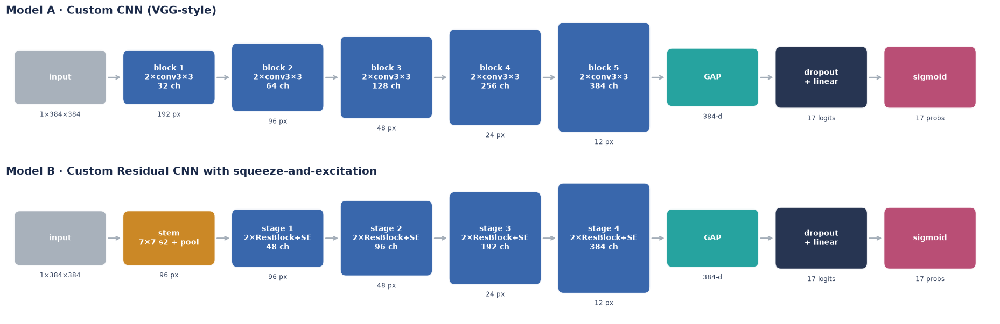

In [27]:
def draw_architecture(blocks, title, ax):
    """blocks: list of (label, sublabel, color, width-scale)."""
    x = 0.0
    for i, (lab_, sub, col, wsc) in enumerate(blocks):
        h = 0.35 + 0.65 * wsc
        ax.add_patch(mpatches.FancyBboxPatch((x, (1 - h) / 2), 0.9, h, boxstyle="round,pad=0.02,rounding_size=0.06",
                                             fc=col, ec="white", lw=2, alpha=0.95))
        ax.text(x + 0.45, 0.5, lab_, ha="center", va="center", color="white", fontsize=9, fontweight="bold", wrap=True)
        ax.text(x + 0.45, (1 - h) / 2 - 0.08, sub, ha="center", va="top", color="#33415C", fontsize=8)
        if i < len(blocks) - 1:
            ax.annotate("", xy=(x + 1.08, 0.5), xytext=(x + 0.92, 0.5), arrowprops=dict(arrowstyle="->", color=GREY, lw=1.5))
        x += 1.1
    ax.set_xlim(-0.1, x); ax.set_ylim(-0.25, 1.05); ax.axis("off"); ax.set_title(title, loc="left")

fig, axes = plt.subplots(2, 1, figsize=(17, 5.6))
draw_architecture([("input", "1×384×384", GREY, 0.2)] +
                  [(f"block {i+1}\n2×conv3×3\n{w} ch", f"{384 // 2**(i+1)} px", BLUE, (i + 1) / 5) for i, w in enumerate(CustomCNN.widths)] +
                  [("GAP", "384-d", TEAL, 0.25), ("dropout\n+ linear", "17 logits", NAVY, 0.3), ("sigmoid", "17 probs", MAGENTA, 0.3)],
                  "Model A · Custom CNN (VGG-style)", axes[0])
draw_architecture([("input", "1×384×384", GREY, 0.2), ("stem\n7×7 s2 + pool", "96 px", AMBER, 0.2)] +
                  [(f"stage {i+1}\n2×ResBlock+SE\n{w} ch", f"{96 // 2**i} px", BLUE, (i + 1) / 4) for i, w in enumerate(CustomResNet.widths)] +
                  [("GAP", "384-d", TEAL, 0.25), ("dropout\n+ linear", "17 logits", NAVY, 0.3), ("sigmoid", "17 probs", MAGENTA, 0.3)],
                  "Model B · Custom Residual CNN with squeeze-and-excitation", axes[1])
plt.tight_layout(); plt.show()

In [28]:
def layer_table(model, in_ch, size=TRAIN_SIZE):
    """Output shape and parameters per top-level stage (forward hooks)."""
    rows, hooks = [], []
    named = [(n, m) for n, m in model.backbone.named_children() if n != "pool"]
    for n, m in named:
        mods = list(m.children()) if isinstance(m, nn.Sequential) and n == "stages" else [m]
        for k, mm in enumerate(mods):
            label = f"{n}[{k}]" if n == "stages" else n
            hooks.append(mm.register_forward_hook(lambda mod, i, o, label=label: rows.append(
                (label, tuple(o.shape[1:]), sum(p.numel() for p in mod.parameters())))))
    with torch.no_grad():
        model.eval()(torch.zeros(1, in_ch, size, size, device=DEVICE))
    for h in hooks: h.remove()
    rows.append(("head (Linear)", (len(FINDINGS),), sum(p.numel() for p in model.head.parameters())))
    return pd.DataFrame(rows, columns=["stage", "output shape (C, H, W)", "parameters"]).set_index("stage")

for name in ["custom_cnn", "custom_resnet"]:
    m = SPECS[name].builder(SPECS[name]).to(DEVICE)
    tot, tr = count_params(m)
    display(Markdown(f"**{SPECS[name].family}** — total parameters: {tot:,} · trainable: {tr:,}"))
    display(layer_table(m, 1))
    del m

**Custom CNN (VGG-style)** — total parameters: 3,392,561 · trainable: 3,392,561

,"output shape (C, H, W)",parameters
stage,,
stages[0],"(32, 192, 192)",9632
stages[1],"(64, 96, 96)",55552
stages[2],"(128, 48, 48)",221696
stages[3],"(256, 24, 24)",885760
stages[4],"(384, 12, 12)",2213376
head (Linear),"(17,)",6545


**Custom Residual CNN + SE** — total parameters: 6,385,637 · trainable: 6,385,637

,"output shape (C, H, W)",parameters
stage,,
stem,"(32, 96, 96)",1632
stages[0],"(48, 96, 96)",79308
stages[1],"(96, 48, 48)",300696
stages[2],"(192, 24, 24)",1200432
stages[3],"(384, 12, 12)",4797024
head (Linear),"(17,)",6545


**Forward pass, step by step (Model B).** A 384×384 radiograph enters the 7×7 stride-2 stem (192 px) and a max-pool
(96 px). Each later stage halves the resolution while doubling the channels, ending with a 12×12×384 map in which each
cell "sees" a large part of the thorax. Global average pooling turns it into one 384-d descriptor, and a linear layer
produces 17 logits — one per finding — passed through 17 independent sigmoids.

### 7.1 · Training the custom models

Both use AdamW (lr 1e-3, weight decay 0.05), cosine decay with one warm-up epoch, batch 32, early stopping on validation
macro PR-AUC. Training from scratch needs more epochs than fine-tuning (budget: 40).

[custom_cnn] found completed run -> loading results
[custom_resnet] found completed run -> loading results


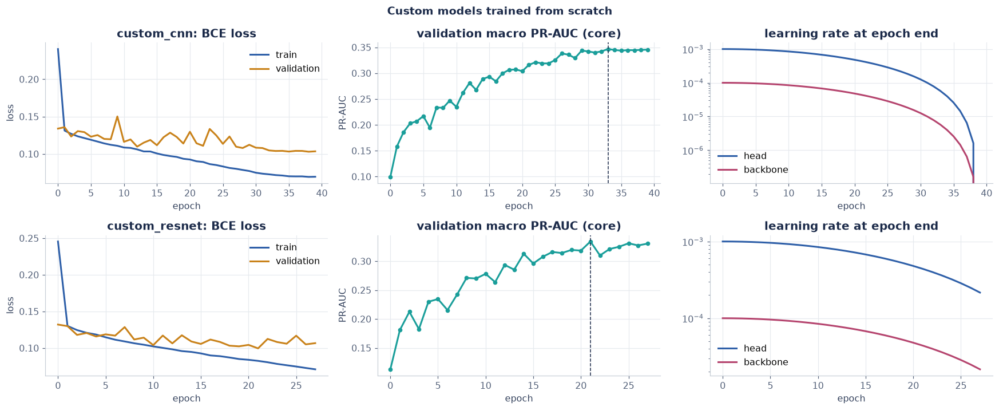

In [29]:
results = {}
for name in ["custom_cnn", "custom_resnet"]:
    results[name] = train_model(name)
plot_history(["custom_cnn", "custom_resnet"], "Custom models trained from scratch")

**How to read these curves.** A training loss that keeps falling while validation loss rises marks over-fitting; the
dashed line is the epoch whose weights were kept. With ~5,000 training images and no pretraining, custom networks are
expected to learn the large, high-contrast findings (pleural effusion, cardiomegaly) and to struggle with subtle
patterns (interstitial, mass). §10 quantifies this against the pretrained models.

## 8 · Transfer Learning: Five Pretrained Models

**Feature extraction vs fine-tuning, with an example.** A radiologist trained on human chests already knows what edges,
ribs and lung texture look like; learning canine thoraces only requires adjusting that knowledge. *Feature extraction*
keeps the pretrained network fixed and trains only a new 17-output head (Stage 1, 3 epochs). *Fine-tuning* then
unfreezes the backbone (Stage 2) with a learning rate 10–20× smaller than the head's, so pretrained features are adapted
gently instead of overwritten.

**Shared protocol (baseline, identical for all five).** 384-px input · AdamW, weight decay 0.05 · Stage 1: head only,
lr 3e-3 · Stage 2: all blocks unfrozen, head lr 1e-3, backbone lr 1e-4 (5e-5 for the two transformers), cosine schedule
with one warm-up epoch · effective batch 32 · early stopping (patience 6) on validation macro PR-AUC (core) · AMP.
Only the PetAI candidates are tuned further (§9), with an equal budget each.

| Model | Pretrained weights | Native resolution | Notes for 8 GB VRAM |
|---|---|---|---|
| CLIP ViT-B/32 | `openai/clip-vit-base-patch32` (vision tower only) | 224 | positional embeddings bicubically interpolated to 384 (12×12 patches) |
| HieraDet-D Small | `birder-project/hieradet_d_small_dino-v2-inat21` | 384 | batch 12 × 3 accumulation, gradient checkpointing |
| EfficientNet-B3 | `timm/efficientnet_b3.ra2_in1k` | 288–320 | batch 16 × 2 |
| DenseNet-121 | `timm/densenet121.tv_in1k` | 224 | batch 16 × 2 |
| ConvNeXt-Tiny | `timm/convnext_tiny.fb_in22k_ft_in1k` | 224 | batch 16 × 2 |

> **Resolution caveat.** All models receive 384 px for a fair comparison. Models pretrained at 224 px see objects at a
> different apparent scale than during pretraining; this is part of what fine-tuning must absorb.

In [30]:
def describe_model(name):
    spec = SPECS[name]; m = spec.builder(spec).to(DEVICE)
    tot, _ = count_params(m)
    set_trainable(m, spec, 1, 1.0); _, s1 = count_params(m)
    set_trainable(m, spec, 2, spec.unfreeze_frac); _, s2 = count_params(m)
    with torch.no_grad():
        z = m.eval()(prepare(torch.zeros(2, 1, CACHE_SIZE, CACHE_SIZE, dtype=torch.uint8), spec, False))
    display(pd.DataFrame({"value": [spec.family, spec.source, f"{tot/1e6:.1f} M", f"{s1:,} (head only)", f"{s2/1e6:.1f} M",
                                    len(m.blocks), f"{spec.input_size} px", tuple(z.shape)]},
                         index=["model", "weights", "parameters", "trainable · stage 1", "trainable · stage 2",
                                "backbone blocks for unfreezing", "input", "output shape (batch 2)"]))
    del m
    if DEVICE.type == "cuda": torch.cuda.empty_cache()

### 8.1 · CLIP ViT-B/32 (PetAI candidate)

The image is cut into 32×32-pixel patches (12×12 = 144 patches at 384 px), each embedded as a token; 12 transformer
layers let every patch attend to every other one. Unlike a CNN, there is no built-in notion of locality, which is
powerful with enough data but data-hungry. The CLIP text tower is discarded: this is supervised fine-tuning with a
sigmoid head, not zero-shot text matching.

In [31]:
describe_model("clip_vit_b32")
results["clip_vit_b32"] = train_model("clip_vit_b32")

G:\Vet_XRay_AI\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 37430.67it/s]

,value
model,CLIP ViT-B/32
weights,Hugging Face openai/clip-vit-base-patch32
parameters,87.5 M
trainable · stage 1,"13,073 (head only)"
trainable · stage 2,87.5 M
backbone blocks for unfreezing,15
input,384 px
output shape (batch 2),"(2, 17)"


[clip_vit_b32] found completed run -> loading results


### 8.2 · HieraDet-D Small (PetAI candidate)

Hiera is a *hierarchical* vision transformer: like a CNN, it works at four resolutions (96 → 48 → 24 → 12 tokens per
side at 384 px), with local windowed attention early and global attention late. These weights were pretrained
self-supervised with DINOv2 and then fine-tuned on 10,000 iNaturalist species, a fine-grained biological task.

In [32]:
describe_model("hieradet_small")
results["hieradet_small"] = train_model("hieradet_small")

[13/Oct/2026 09:05:48.0451 INFO fs_ops.py:644 ] Loading model from G:\VetXRay_cache\pretrained\hieradet_d_small_dino-v2-inat21.pt on device cpu...


,value
model,HieraDet-D Small
weights,Birder hieradet_d_small_dino-v2-inat21
parameters,34.0 M
trainable · stage 1,"13,073 (head only)"
trainable · stage 2,34.0 M
backbone blocks for unfreezing,6
input,384 px
output shape (batch 2),"(2, 17)"


[hieradet_small] found completed run -> loading results


### 8.3 · EfficientNet-B3 (PetAI candidate)

EfficientNet scales depth, width and resolution together with a single coefficient and uses inverted-residual
(MBConv) blocks with squeeze-and-excitation, giving strong accuracy per FLOP — a natural deployment candidate.

In [33]:
describe_model("efficientnet_b3")
results["efficientnet_b3"] = train_model("efficientnet_b3")

,value
model,EfficientNet-B3
weights,timm efficientnet_b3.ra2_in1k
parameters,10.7 M
trainable · stage 1,"26,129 (head only)"
trainable · stage 2,10.7 M
backbone blocks for unfreezing,9
input,384 px
output shape (batch 2),"(2, 17)"


[efficientnet_b3] found completed run -> loading results


### 8.4 · DenseNet-121 (comparison)

Every layer receives the feature maps of all preceding layers in its block, encouraging feature reuse. It is the
architecture of CheXNet and one of the two networks used in the original VetXRay canine study.

In [34]:
describe_model("densenet121")
results["densenet121"] = train_model("densenet121")

,value
model,DenseNet-121
weights,timm densenet121.tv_in1k
parameters,7.0 M
trainable · stage 1,"17,425 (head only)"
trainable · stage 2,7.0 M
backbone blocks for unfreezing,11
input,384 px
output shape (batch 2),"(2, 17)"


[densenet121] found completed run -> loading results


### 8.5 · ConvNeXt-Tiny (comparison)

ConvNeXt modernises ResNet with transformer-era choices (7×7 depthwise convolutions, LayerNorm, GELU, inverted
bottlenecks) while staying a pure CNN.

In [35]:
describe_model("convnext_tiny")
results["convnext_tiny"] = train_model("convnext_tiny")

,value
model,ConvNeXt-Tiny
weights,timm convnext_tiny.fb_in22k_ft_in1k
parameters,27.8 M
trainable · stage 1,"13,073 (head only)"
trainable · stage 2,27.8 M
backbone blocks for unfreezing,6
input,384 px
output shape (batch 2),"(2, 17)"


[convnext_tiny] found completed run -> loading results


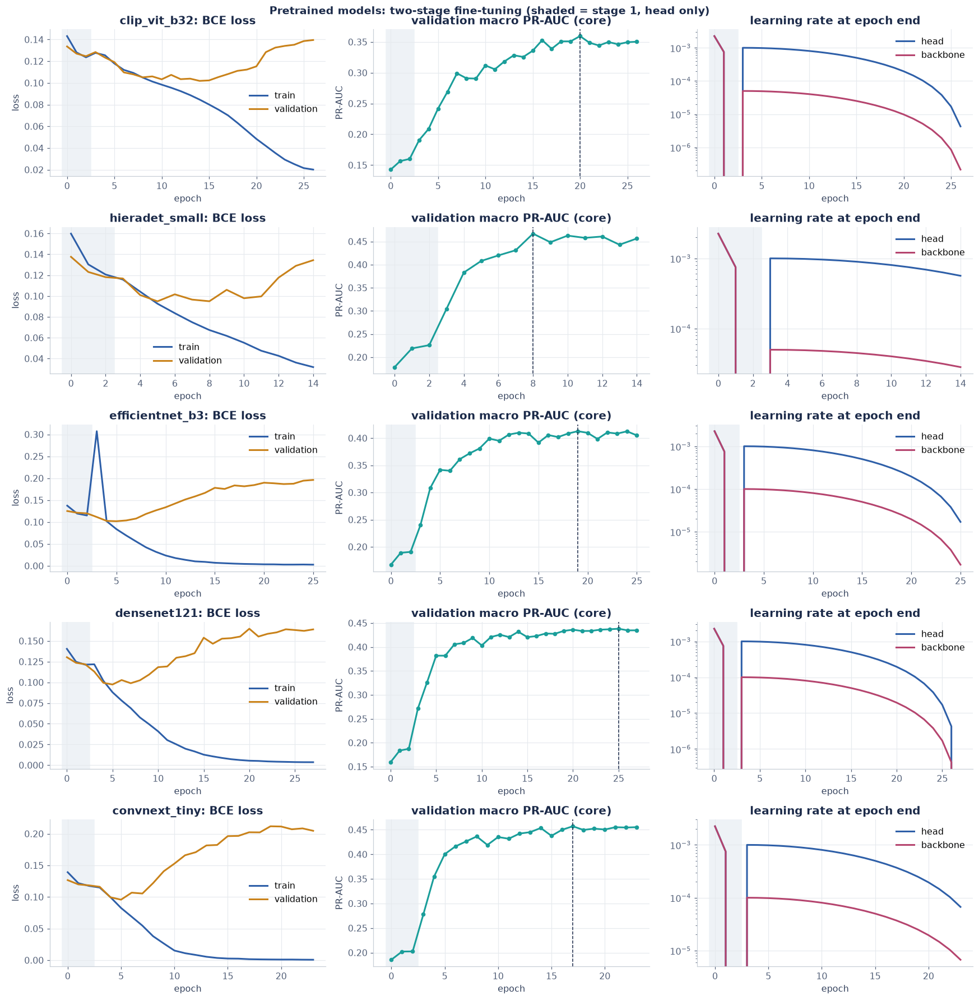

In [36]:
plot_history(["clip_vit_b32", "hieradet_small", "efficientnet_b3", "densenet121", "convnext_tiny"],
             "Pretrained models: two-stage fine-tuning (shaded = stage 1, head only)")

**Reading the fine-tuning curves.** In the shaded stage the backbone is frozen, so validation PR-AUC rises quickly and
then plateaus: this is how much the *unchanged* pretrained features already know about canine and feline thoraces.
The jump after unfreezing measures the value of adapting the backbone. A widening gap between training and validation
loss in stage 2 is the signal for early stopping.

## 9 · Hyperparameter Optimisation (PetAI candidates)

**What is tuned and why** (following the Tuning Playbook, the *scientific* question — which architecture? — is fixed;
only *nuisance* hyperparameters are searched):

| Hyperparameter | What it does | Raise it when… | Lower it when… | Search range |
|---|---|---|---|---|
| Head learning rate | step size of the new layer | loss decreases very slowly | loss oscillates or explodes | 1e-4 – 3e-3 (log) |
| Backbone / head lr ratio | how much pretrained features may move | the frozen-feature plateau is low | validation drops right after unfreezing | 0.02 – 0.3 (log) |
| Weight decay | pulls weights toward zero (regularisation) | train ≫ validation performance | both are poor (under-fitting) | 1e-4 – 0.2 (log) |
| Dropout before the head | randomly hides features | over-fitting | under-fitting | 0 – 0.4 |
| Unfreeze depth | fraction of backbone blocks trained in stage 2 | features too "natural-image" specific | small data, over-fitting | {50 %, 100 %} |
| `pos_weight` | up-weights positives of rare findings (√(neg/pos), capped at 10) | rare findings are never predicted | false positives dominate | {off, on} |

Batch size is fixed by the GPU (and not tuned: it interacts with the learning rate rather than being a quality knob
on its own). **Search method:** Optuna TPE (Bayesian) with 4 random start-up trials and a median pruner that stops trials
falling below the median of earlier trials at the same epoch. **Budget:** 12 trials × (1 + 5) epochs per candidate,
identical for all three. Every trial is scored on the validation set; the test set is never touched. The study is
stored in SQLite, so an interrupted search resumes where it stopped.

In [37]:
import optuna
from optuna.samplers import TPESampler
from optuna.pruners import MedianPruner
optuna.logging.set_verbosity(optuna.logging.WARNING)

OPTUNA_TRIALS = {"SMOKE": 2, "FULL": 12}[RUN_MODE]
OPTUNA_BUDGET = {"SMOKE": dict(e1=1, e2=1, scratch=1, patience=1, max_batches=3, warmup=0),
                 "FULL": dict(e1=1, e2=5, scratch=0, patience=3, max_batches=None, warmup=0)}[RUN_MODE]
OPTUNA_DB = f"sqlite:///{(WORK_DIR / 'optuna.db').as_posix()}"

def objective(trial, name):
    hp = {"lr_head": trial.suggest_float("lr_head", 1e-4, 3e-3, log=True),
          "lr_ratio": trial.suggest_float("lr_ratio", 0.02, 0.3, log=True),
          "wd": trial.suggest_float("wd", 1e-4, 0.2, log=True),
          "drop": trial.suggest_float("drop", 0.0, 0.4),
          "unfreeze_frac": trial.suggest_categorical("unfreeze_frac", [0.5, 1.0]),
          "pos_weight": trial.suggest_categorical("pos_weight", [False, True])}
    r = train_model(name, run_name=f"optuna_{name}", hp=hp, budget=OPTUNA_BUDGET, trial=trial, save=False, verbose=False)
    return r["best_val_macro_PR_AUC_core"]

def tune(name):
    study = optuna.create_study(direction="maximize", study_name=f"{RUN_MODE}_{name}", storage=OPTUNA_DB, load_if_exists=True,
                                sampler=TPESampler(seed=SEED, n_startup_trials=4),
                                pruner=MedianPruner(n_startup_trials=3, n_warmup_steps=2))
    done = sum(t.state in (optuna.trial.TrialState.COMPLETE, optuna.trial.TrialState.PRUNED) for t in study.trials)
    if OPTUNA_TRIALS - done > 0:
        t0 = time.time()
        study.optimize(lambda t: objective(t, name), n_trials=OPTUNA_TRIALS - done, gc_after_trial=True)
        print(f"[{name}] {OPTUNA_TRIALS - done} trials in {(time.time()-t0)/60:.1f} min")
    return study

studies = {}
for name in CANDIDATES:
    studies[name] = tune(name)
    print(f"[{name}] best trial #{studies[name].best_trial.number}: val macro PR-AUC(core) = {studies[name].best_value:.4f} | {studies[name].best_params}")

[clip_vit_b32] best trial #2: val macro PR-AUC(core) = 0.3645 | {'lr_head': 0.0002814509271606064, 'lr_ratio': 0.08283072221077194, 'wd': 0.002666020367873238, 'drop': 0.11649165607921677, 'unfreeze_frac': 0.5, 'pos_weight': True}


[hieradet_small] best trial #8: val macro PR-AUC(core) = 0.4551 | {'lr_head': 0.001294598740870404, 'lr_ratio': 0.028742970528277564, 'wd': 0.08736212246968031, 'drop': 0.13284257987777734, 'unfreeze_frac': 0.5, 'pos_weight': True}
[efficientnet_b3] best trial #12: val macro PR-AUC(core) = 0.4253 | {'lr_head': 0.002032331674968374, 'lr_ratio': 0.14889775286687382, 'wd': 0.0038334646906027507, 'drop': 0.043096364847340404, 'unfreeze_frac': 1.0, 'pos_weight': True}


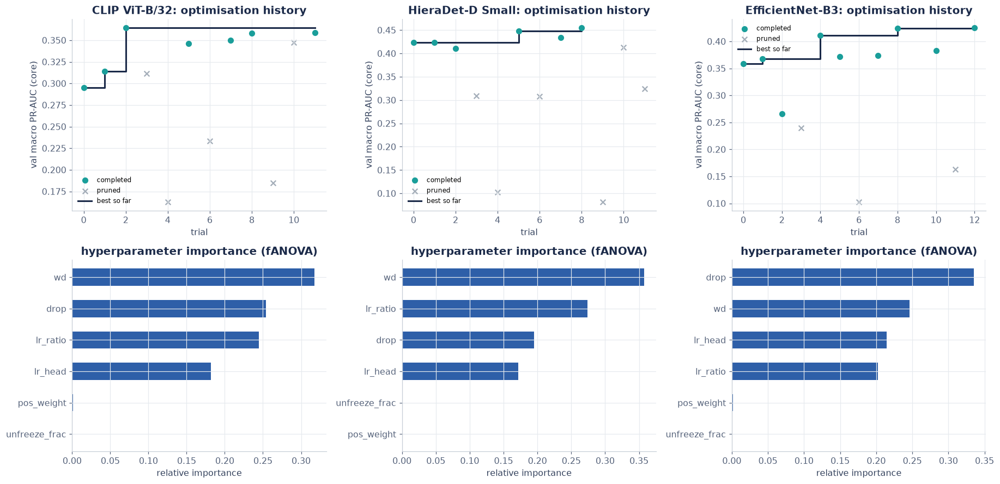

In [38]:
fig, axes = plt.subplots(2, len(CANDIDATES), figsize=(5.6 * len(CANDIDATES), 8.2), squeeze=False)
for j, name in enumerate(CANDIDATES):
    tdf = studies[name].trials_dataframe()
    comp = tdf[tdf.state == "COMPLETE"]; prun = tdf[tdf.state == "PRUNED"]
    a = axes[0, j]
    a.scatter(comp.number, comp.value, color=TEAL, s=40, label="completed", zorder=3)
    if len(prun):
        a.scatter(prun.number, [np.nan] * len(prun) if prun.value.isna().all() else prun.value, marker="x", color=GREY, s=40, label="pruned")
    a.plot(comp.number, comp.value.cummax(), color=NAVY, lw=2, drawstyle="steps-post", label="best so far")
    a.set(title=f"{SPECS[name].family}: optimisation history", xlabel="trial", ylabel="val macro PR-AUC (core)"); a.legend(fontsize=8)
    a = axes[1, j]
    try:
        imp = optuna.importance.get_param_importances(studies[name])
        a.barh(list(imp)[::-1], list(imp.values())[::-1], color=BLUE, height=0.55)
        a.set(title="hyperparameter importance (fANOVA)", xlabel="relative importance")
    except Exception as e:
        a.text(0.5, 0.5, f"importance not estimable\n({type(e).__name__}: too few completed trials)", ha="center", va="center", transform=a.transAxes, color=GREY)
        a.axis("off")
if RUN_MODE == "SMOKE":
    fig.suptitle("SMOKE TEST — trial values are technical checks only", color=MAGENTA, fontweight="bold")
plt.tight_layout(); plt.show()

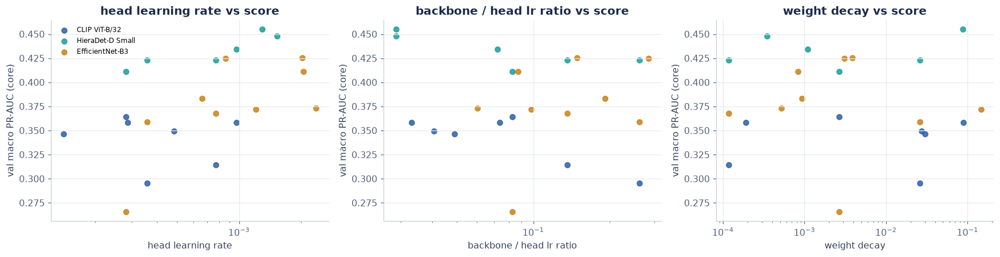

In [39]:
import matplotlib.ticker
if all(len(studies[n].trials) for n in CANDIDATES):
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for name, col in zip(CANDIDATES, [BLUE, TEAL, AMBER]):
        tdf = studies[name].trials_dataframe(); tdf = tdf[tdf.state == "COMPLETE"]
        for a, p in zip(axes, ["params_lr_head", "params_lr_ratio", "params_wd"]):
            a.scatter(tdf[p], tdf.value, color=col, s=36, alpha=0.85, label=SPECS[name].family)
    for a, p in zip(axes, ["head learning rate", "backbone / head lr ratio", "weight decay"]):
        a.set_xscale("log"); a.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); a.set(xlabel=p, ylabel="val macro PR-AUC (core)", title=f"{p} vs score")
    axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()

**Interpreting the search.** The history plot shows whether the search was still improving when the budget ended (a
flat "best so far" line means more trials would likely not help). Importance values are only estimates from a dozen
trials; they indicate which knobs mattered *in this range*, not universally. Best parameters at the edge of a range
would suggest widening it.

Each candidate is now retrained with its best configuration and the full fine-tuning budget.

[clip_vit_b32_tuned] found completed run -> loading results
[hieradet_small_tuned] found completed run -> loading results
[efficientnet_b3_tuned] found completed run -> loading results


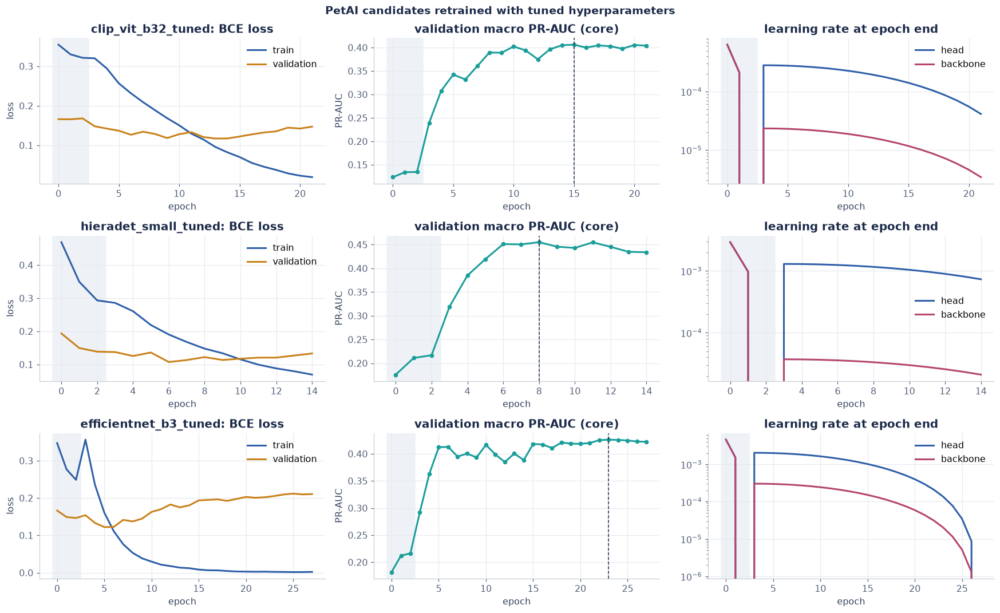

In [40]:
for name in CANDIDATES:
    results[f"{name}_tuned"] = train_model(name, run_name=f"{name}_tuned", hp=studies[name].best_params)
plot_history([f"{n}_tuned" for n in CANDIDATES], "PetAI candidates retrained with tuned hyperparameters")

## 10 · Validation Comparison and PetAI Model Selection

**Selection protocol (fixed before any test-set evaluation).**

1. Primary criterion: validation macro PR-AUC over the core findings.
2. Only the three PetAI candidates are eligible (baseline or tuned run, whichever is better on validation).
3. If two candidates are within 0.005 of each other, the one with lower inference latency wins (deployment cost).
4. The choice is written to `petai_selection.json` *before* §11 computes any test metric.

Validation predictions are recomputed here from the saved best weights, and the per-finding thresholds are fitted on
them.

In [41]:
ALL_RUNS = ["custom_cnn", "custom_resnet", "clip_vit_b32", "hieradet_small", "efficientnet_b3", "densenet121", "convnext_tiny"] + \
           [f"{n}_tuned" for n in CANDIDATES]

def eval_split(run_name, split):
    """Probabilities for a split, cached per run."""
    f = RUNS_DIR / run_name / f"{split}_probs_full.npz"
    if f.exists():
        z = np.load(f); return z["p"], z["y"]
    model, spec, _ = load_trained(run_name)
    p, y, _ = predict_probs(model, make_loader(split, 32, False), spec)
    np.savez(f, p=p, y=y); del model
    if DEVICE.type == "cuda": torch.cuda.empty_cache()
    return p, y

rows, VAL = [], {}
for r in ALL_RUNS:
    if not (RUNS_DIR / r / "summary.json").exists():
        rows.append({"run": r, "status": "NOT RUN"}); continue
    s = json.loads((RUNS_DIR / r / "summary.json").read_text())
    pv, yv = eval_split(r, "val"); thr = fit_thresholds(yv, pv)
    np.save(RUNS_DIR / r / "thresholds.npy", thr); VAL[r] = (pv, yv, thr)
    m = summary_metrics(yv, pv, thr)
    rows.append({"run": r, "status": "done", "model": s["family"], "PetAI candidate": SPECS[s["model"]].petai_candidate,
                 "val macro PR-AUC (core)": m["macro_PR_AUC_core"], "val macro ROC-AUC (core)": m["macro_ROC_AUC_core"],
                 "val macro F1 (core)": m["macro_F1_core"], "val micro F1": m["micro_F1"], "best epoch": s["best_epoch"],
                 "train min": s["train_minutes"], "params (M)": s["params_total"] / 1e6, "latency ms": s["latency_ms_bs1"],
                 "peak VRAM GB": s["peak_vram_gb"]})
val_table = pd.DataFrame(rows).set_index("run")
display(val_table.style.format(precision=3, na_rep="—").background_gradient(subset=["val macro PR-AUC (core)"], cmap=sns.light_palette(TEAL, as_cmap=True)))

,status,model,PetAI candidate,val macro PR-AUC (core),val macro ROC-AUC (core),val macro F1 (core),val micro F1,best epoch,train min,params (M),latency ms,peak VRAM GB
run,,,,,,,,,,,,
custom_cnn,done,Custom CNN (VGG-style),False,0.347,0.801,0.376,0.427,33,28.766,3.393,14.596,3.983
custom_resnet,done,Custom Residual CNN + SE,False,0.334,0.788,0.368,0.263,21,8.393,6.386,10.886,1.061
clip_vit_b32,done,CLIP ViT-B/32,True,0.359,0.810,0.405,0.407,20,18.853,87.469,10.703,2.773
hieradet_small,done,HieraDet-D Small,True,0.467,0.869,0.496,0.527,8,23.603,33.962,13.169,1.451
efficientnet_b3,done,EfficientNet-B3,True,0.413,0.842,0.436,0.410,19,28.148,10.722,15.773,4.290
densenet121,done,DenseNet-121,False,0.438,0.854,0.494,0.378,25,29.104,6.971,25.181,3.317
convnext_tiny,done,ConvNeXt-Tiny,False,0.457,0.849,0.494,0.462,17,24.288,27.833,9.324,3.539
clip_vit_b32_tuned,done,CLIP ViT-B/32,True,0.406,0.814,0.435,0.461,15,10.993,87.469,9.456,1.772
hieradet_small_tuned,done,HieraDet-D Small,True,0.455,0.856,0.502,0.450,8,20.968,33.962,10.609,1.441


In [42]:
SEL_FILE = RUNS_DIR / "petai_selection.json"
cand = val_table[(val_table.status == "done") & (val_table["PetAI candidate"] == True)].copy()
if len(cand):
    cand = cand.sort_values("val macro PR-AUC (core)", ascending=False)
    top = cand.iloc[0]
    close = cand[cand["val macro PR-AUC (core)"] >= top["val macro PR-AUC (core)"] - 0.005]
    winner = close.sort_values("latency ms").index[0]
    selection = {"run": winner, "model": json.loads((RUNS_DIR / winner / "summary.json").read_text())["model"],
                 "criterion": "validation macro PR-AUC (core); latency tie-break within 0.005",
                 "val_macro_PR_AUC_core": float(cand.loc[winner, "val macro PR-AUC (core)"]),
                 "ranking": cand["val macro PR-AUC (core)"].round(4).to_dict(), "mode": RUN_MODE,
                 "locked_at": time.strftime("%Y-%m-%d %H:%M:%S")}
    if not SEL_FILE.exists():
        SEL_FILE.write_text(json.dumps(selection, indent=1))
    selection = json.loads(SEL_FILE.read_text())
    display(Markdown(f"**Selected PetAI model:** `{selection['run']}` ({SPECS[selection['model']].family}) — "
                     f"validation macro PR-AUC (core) = {selection['val_macro_PR_AUC_core']:.3f}. Locked at {selection['locked_at']}."
                     + ("  \n*SMOKE mode: this is a pipeline check, not a scientific selection.*" if RUN_MODE == "SMOKE" else "")))
else:
    selection = None
    print("No PetAI candidate has finished training yet; selection postponed.")

**Selected PetAI model:** `hieradet_small` (HieraDet-D Small) — validation macro PR-AUC (core) = 0.467. Locked at 2026-10-13 08:59:56.

## 11 · Final Test-Set Evaluation (run once, after selection)

All runs are evaluated on the held-out test animals with the thresholds frozen from validation. 95 % confidence
intervals resample **animals**, not images, so correlated views of the same animal are not counted as independent
evidence.

In [43]:
test_groups = work.loc[work.split == "test", "group"].to_numpy()
TEST, rows = {}, []
for r in ALL_RUNS:
    if r not in VAL:
        continue
    pt, yt = eval_split(r, "test"); thr = VAL[r][2]; TEST[r] = (pt, yt)
    m = summary_metrics(yt, pt, thr)
    lo, hi = group_bootstrap_ci(yt, pt, test_groups, macro_ap_core, n=1000 if RUN_MODE == "FULL" else 50)
    rows.append({"run": r, "model": SPECS[json.loads((RUNS_DIR / r / 'summary.json').read_text())["model"]].family,
                 "test macro PR-AUC (core)": m["macro_PR_AUC_core"], "95% CI": f"{lo:.3f}–{hi:.3f}", "ci_lo": lo, "ci_hi": hi,
                 "test macro ROC-AUC (core)": m["macro_ROC_AUC_core"], "test macro F1 (core)": m["macro_F1_core"],
                 "test micro PR-AUC": m["micro_PR_AUC"], "test micro F1": m["micro_F1"],
                 "sensitivity (core)": m["macro_sensitivity_core"], "specificity (core)": m["macro_specificity_core"],
                 "Brier (core)": m["brier_core"], "macro PR-AUC (all defined)": m["macro_PR_AUC_all_defined"]})
test_table = pd.DataFrame(rows).set_index("run") if rows else pd.DataFrame()
if len(test_table):
    display(test_table.drop(columns=["ci_lo", "ci_hi"]).style.format(precision=3, na_rep="—"))

,model,test macro PR-AUC (core),95% CI,test macro ROC-AUC (core),test macro F1 (core),test micro PR-AUC,test micro F1,sensitivity (core),specificity (core),Brier (core),macro PR-AUC (all defined)
run,,,,,,,,,,,
custom_cnn,Custom CNN (VGG-style),0.328,0.289–0.384,0.825,0.325,0.488,0.377,0.375,0.936,0.046,0.211
custom_resnet,Custom Residual CNN + SE,0.347,0.311–0.387,0.792,0.354,0.515,0.253,0.552,0.849,0.046,0.242
clip_vit_b32,CLIP ViT-B/32,0.375,0.338–0.422,0.810,0.390,0.494,0.375,0.448,0.939,0.047,0.266
hieradet_small,HieraDet-D Small,0.492,0.430–0.534,0.874,0.475,0.590,0.501,0.549,0.942,0.041,0.348
efficientnet_b3,EfficientNet-B3,0.416,0.363–0.468,0.829,0.412,0.493,0.375,0.442,0.944,0.050,0.270
densenet121,DenseNet-121,0.476,0.418–0.529,0.860,0.472,0.548,0.376,0.500,0.957,0.047,0.379
convnext_tiny,ConvNeXt-Tiny,0.460,0.400–0.520,0.864,0.438,0.571,0.432,0.499,0.947,0.047,0.367
clip_vit_b32_tuned,CLIP ViT-B/32,0.428,0.362–0.485,0.842,0.407,0.508,0.435,0.427,0.942,0.053,0.295
hieradet_small_tuned,HieraDet-D Small,0.488,0.430–0.536,0.877,0.467,0.535,0.415,0.536,0.945,0.058,0.324


## 12 · Results in Pictures

### 12.1 · Model comparison

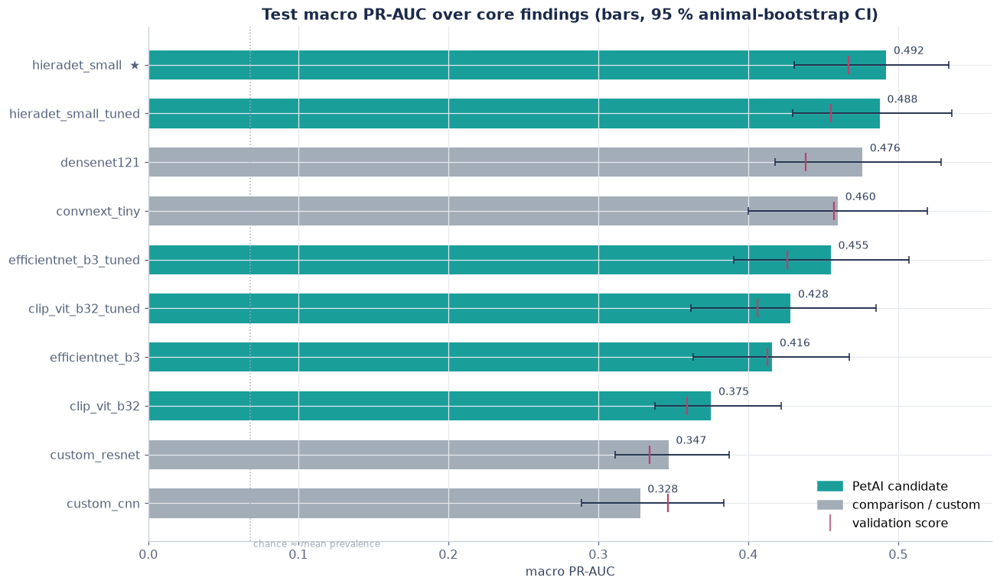

In [44]:
if len(test_table):
    t = test_table.join(val_table[["val macro PR-AUC (core)"]]).sort_values("test macro PR-AUC (core)")
    is_cand = [SPECS[json.loads((RUNS_DIR / r / "summary.json").read_text())["model"]].petai_candidate for r in t.index]
    fig, ax = plt.subplots(figsize=(12, 0.55 * len(t) + 1.6))
    y = np.arange(len(t))
    ax.barh(y, t["test macro PR-AUC (core)"], color=[TEAL if c else GREY for c in is_cand], height=0.6)
    ax.errorbar(t["test macro PR-AUC (core)"], y, xerr=np.clip([t["test macro PR-AUC (core)"] - t.ci_lo, t.ci_hi - t["test macro PR-AUC (core)"]], 0, None),
                fmt="none", ecolor=NAVY, capsize=3, lw=1.2)
    ax.scatter(t["val macro PR-AUC (core)"], y, marker="|", s=260, color=MAGENTA, zorder=4, label="validation score")
    for yi, v in zip(y, t["test macro PR-AUC (core)"]):
        ax.text(v + 0.005, yi + 0.22, f"{v:.3f}", fontsize=9, color="#33415C")
    ax.set_yticks(y, [f"{r}{'  ★' if selection and r == selection['run'] else ''}" for r in t.index])
    prev = Y_work[(work.split == "test").values][:, [FINDINGS.index(f) for f in CORE]].mean()
    ax.axvline(prev, color=GREY, ls=":", lw=1); ax.text(prev, -0.9, " chance ≈ mean prevalence", color=GREY, fontsize=8)
    ax.set(title="Test macro PR-AUC over core findings (bars, 95 % animal-bootstrap CI)", xlabel="macro PR-AUC")
    ax.legend(handles=[mpatches.Patch(color=TEAL, label="PetAI candidate"), mpatches.Patch(color=GREY, label="comparison / custom"),
                       plt.Line2D([], [], color=MAGENTA, marker="|", ls="", ms=14, label="validation score")], loc="lower right")
    plt.tight_layout(); plt.show()

**Interpretation guide.** Bars are test scores; the magenta tick is the same model's validation score. A tick far to the
right of its bar indicates that the model (or its threshold/hyperparameter search) fitted the validation set more than
the data justify. Overlapping confidence intervals mean the ranking between those models is not statistically
established on ~1,100 test images.

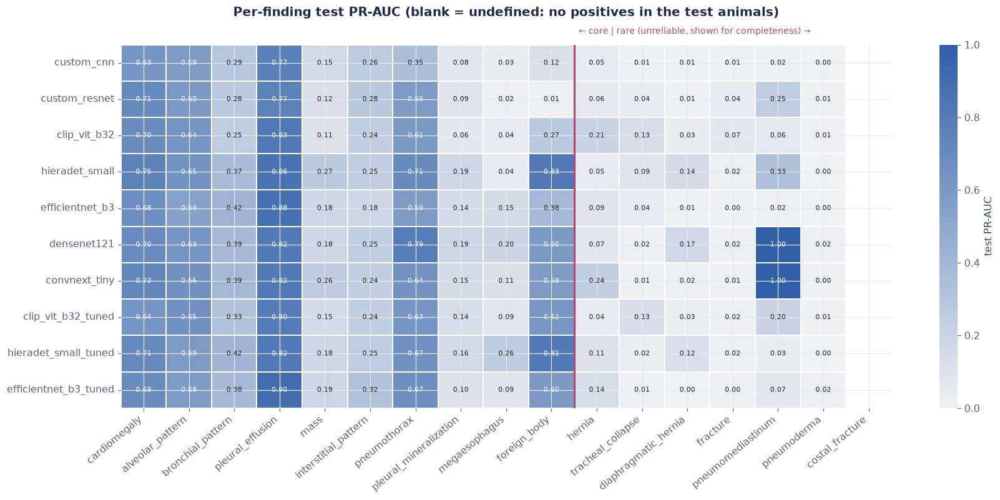

In [45]:
if len(test_table):
    runs = test_table.index.tolist()
    H = pd.DataFrame({r: per_label_metrics(TEST[r][1], TEST[r][0], VAL[r][2])["PR-AUC"] for r in runs}).T
    order_f = lab.index.tolist()
    fig, ax = plt.subplots(figsize=(16, 0.5 * len(runs) + 2.4))
    sns.heatmap(H[order_f], annot=True, fmt=".2f", annot_kws={"fontsize": 7.5}, cmap=sns.light_palette(BLUE, as_cmap=True),
                vmin=0, vmax=1, linewidths=1, linecolor="white", cbar_kws={"label": "test PR-AUC"}, ax=ax)
    ax.axvline(len(CORE), color=MAGENTA, lw=2)
    ax.text(len(CORE) + 0.1, -0.3, "← core | rare (unreliable, shown for completeness) →", color=MAGENTA, fontsize=9)
    ax.set_title("Per-finding test PR-AUC (blank = undefined: no positives in the test animals)", pad=30); ax.set(xlabel="", ylabel="")
    plt.xticks(rotation=40, ha="right"); plt.tight_layout(); plt.show()

### 12.2 · Cost versus quality

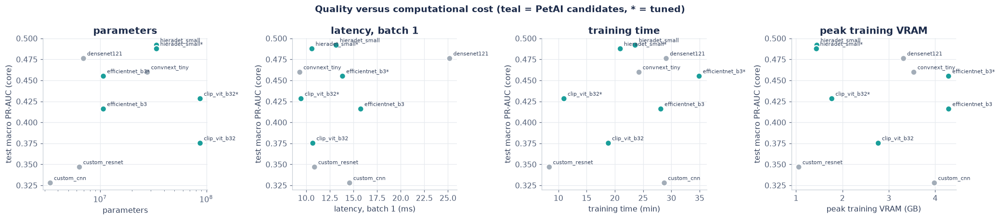

In [46]:
if len(test_table):
    S = pd.DataFrame({r: json.loads((RUNS_DIR / r / "summary.json").read_text()) for r in test_table.index}).T
    S["score"] = test_table["test macro PR-AUC (core)"]
    fig, axes = plt.subplots(1, 4, figsize=(19, 4.2))
    for a, col, lab_x in zip(axes, ["params_total", "latency_ms_bs1", "train_minutes", "peak_vram_gb"],
                             ["parameters", "latency, batch 1 (ms)", "training time (min)", "peak training VRAM (GB)"]):
        vals = pd.to_numeric(S[col], errors="coerce")
        cand_mask = [SPECS[m].petai_candidate for m in S["model"]]
        a.scatter(vals, S.score, s=70, c=[TEAL if c else GREY for c in cand_mask], edgecolor="white", lw=1.5, zorder=3)
        for r, xv, yv in zip(S.index, vals, S.score):
            a.annotate(r.replace("_tuned", "*"), (xv, yv), textcoords="offset points", xytext=(5, 4), fontsize=7.5, color="#33415C")
        if col == "params_total": a.set_xscale("log")
        a.set(xlabel=lab_x, ylabel="test macro PR-AUC (core)", title=lab_x.split(" (")[0])
    fig.suptitle("Quality versus computational cost (teal = PetAI candidates, * = tuned)", color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()

### 12.3 · The selected model in detail

**hieradet_small** — per-finding test metrics with validation-frozen thresholds

,tier,n_pos,PR-AUC,ROC-AUC,threshold,precision,sensitivity,specificity,F1,TP,FP,FN,TN
finding,,,,,,,,,,,,,
alveolar_pattern,core,153,0.651,0.921,0.212,0.587,0.752,0.919,0.659,115,81,38,922
bronchial_pattern,core,104,0.368,0.822,0.153,0.274,0.654,0.829,0.386,68,180,36,872
cardiomegaly,core,262,0.755,0.882,0.497,0.724,0.592,0.934,0.651,155,59,107,835
costal_fracture,rare,0,—,—,0.500,—,—,1.000,—,0,0,0,1156
diaphragmatic_hernia,rare,2,0.143,0.976,0.006,0.111,0.500,0.993,0.182,1,8,1,1146
foreign_body,core,11,0.826,0.983,0.519,1.000,0.727,1.000,0.842,8,0,3,1145
fracture,rare,2,0.022,0.929,0.008,0.000,0.000,0.995,0.000,0,6,2,1148
hernia,rare,5,0.050,0.936,0.033,0.000,0.000,0.992,0.000,0,9,5,1142
interstitial_pattern,core,58,0.254,0.845,0.210,0.202,0.621,0.871,0.305,36,142,22,956


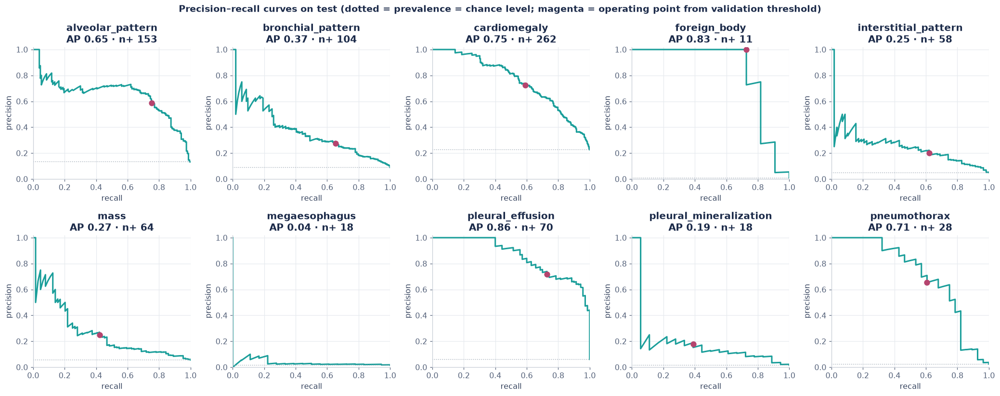

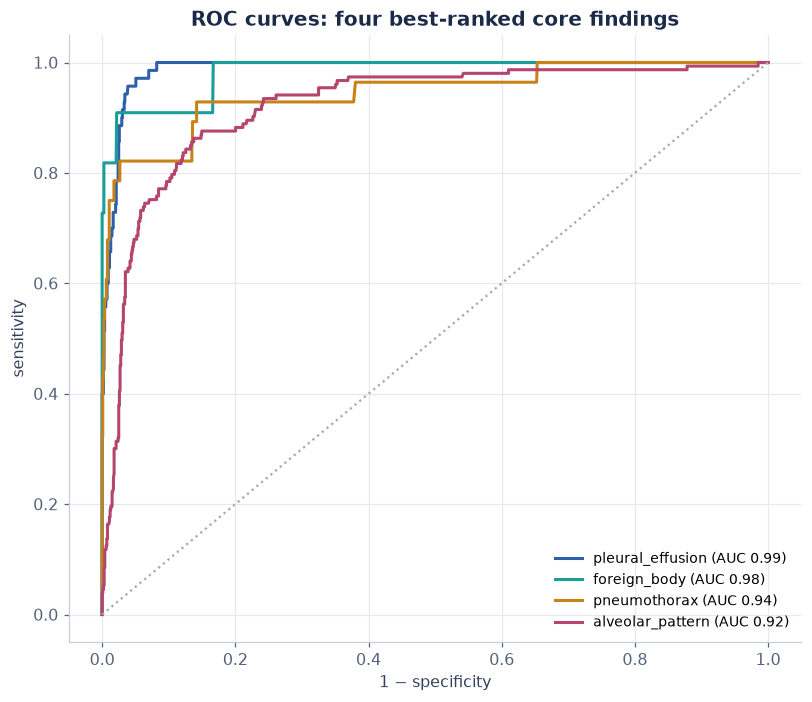

In [47]:
if selection and selection["run"] in TEST:
    R = selection["run"]; pt, yt = TEST[R]; pv, yv, thr = VAL[R]
    per = per_label_metrics(yt, pt, thr)
    display(Markdown(f"**{R}** — per-finding test metrics with validation-frozen thresholds"))
    display(per.style.format({c: "{:.3f}" for c in ["PR-AUC", "ROC-AUC", "threshold", "precision", "sensitivity", "specificity", "F1"]}, na_rep="—"))

    fig, axes = plt.subplots(2, 5, figsize=(19, 7.6))
    for a, f in zip(axes.flat, CORE):
        j = FINDINGS.index(f)
        if 0 < yt[:, j].sum() < len(yt):
            pr, rc, _ = precision_recall_curve(yt[:, j], pt[:, j])
            a.plot(rc, pr, color=TEAL, lw=2)
            a.axhline(yt[:, j].mean(), color=GREY, ls=":", lw=1)
            sens, prec_ = per.loc[f, "sensitivity"], per.loc[f, "precision"]
            a.scatter([sens], [prec_], color=MAGENTA, s=50, zorder=4)
        a.set(title=f"{f}\nAP {per.loc[f,'PR-AUC']:.2f} · n+ {int(per.loc[f,'n_pos'])}", xlabel="recall", ylabel="precision", xlim=(0, 1), ylim=(0, 1.02))
    fig.suptitle("Precision–recall curves on test (dotted = prevalence = chance level; magenta = operating point from validation threshold)",
                 color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()

    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    pal = [BLUE, TEAL, AMBER, MAGENTA]
    for f, col in zip(per.loc[CORE].sort_values("ROC-AUC", ascending=False).index[:4], pal):
        j = FINDINGS.index(f); fpr, tpr, _ = roc_curve(yt[:, j], pt[:, j])
        ax.plot(fpr, tpr, lw=2, color=col, label=f"{f} (AUC {per.loc[f, 'ROC-AUC']:.2f})")
    ax.plot([0, 1], [0, 1], ls=":", color=GREY)
    ax.set(title="ROC curves: four best-ranked core findings", xlabel="1 − specificity", ylabel="sensitivity"); ax.legend(loc="lower right", fontsize=9)
    plt.tight_layout(); plt.show()

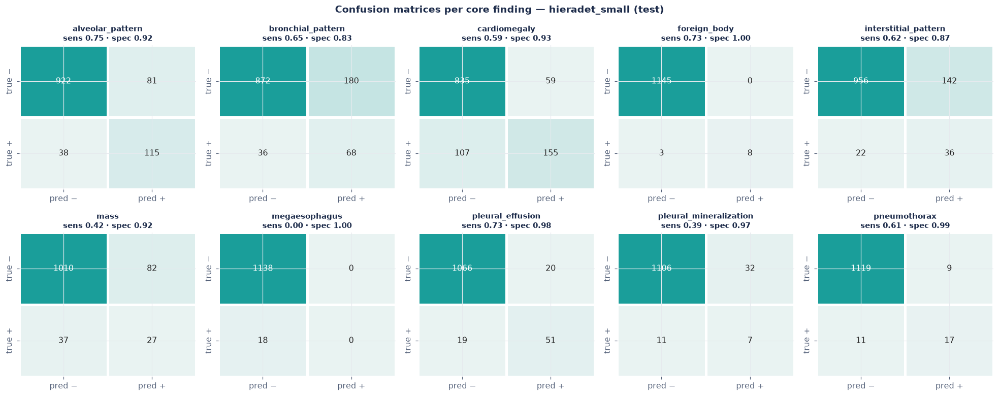

In [48]:
if selection and selection["run"] in TEST:
    fig, axes = plt.subplots(2, 5, figsize=(18, 7.2))
    for a, f in zip(axes.flat, CORE):
        r_ = per.loc[f]; cm = np.array([[r_.TN, r_.FP], [r_.FN, r_.TP]])
        sns.heatmap(cm, annot=True, fmt="d", cbar=False, cmap=sns.light_palette(TEAL, as_cmap=True), linewidths=2, linecolor="white",
                    xticklabels=["pred −", "pred +"], yticklabels=["true −", "true +"], ax=a)
        a.set_title(f"{f}\nsens {r_.sensitivity:.2f} · spec {r_.specificity:.2f}", fontsize=10)
    fig.suptitle(f"Confusion matrices per core finding — {selection['run']} (test)", color=NAVY, fontweight="bold")
    plt.tight_layout(); plt.show()

**Reading the matrices.** Each finding is its own binary decision, so there are ten 2×2 matrices rather than one
17×17 matrix. Thresholds were tuned to maximise F1 on validation; a clinical deployment might instead fix a minimum
sensitivity for urgent findings (pneumothorax, pleural effusion) and accept more false positives.

### 12.4 · Calibration

A model is *calibrated* if, among films it scores 0.7, about 70 % truly have the finding. Calibration matters when the
probability itself is shown to a clinician.

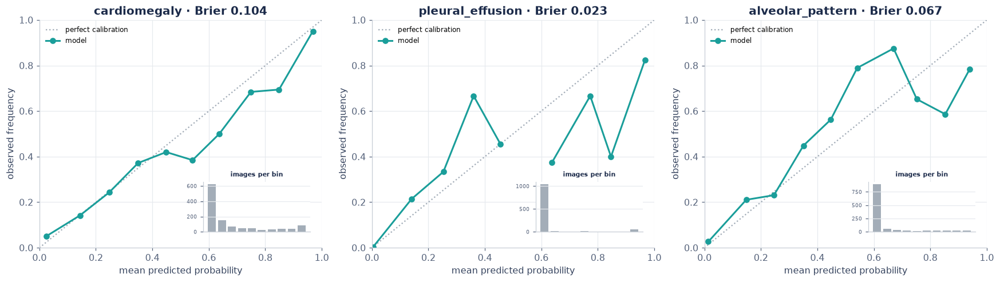

In [49]:
if selection and selection["run"] in TEST:
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
    for a, f in zip(axes, ["cardiomegaly", "pleural_effusion", "alveolar_pattern"]):
        j = FINDINGS.index(f); bins = np.linspace(0, 1, 11); idx = np.clip(np.digitize(pt[:, j], bins) - 1, 0, 9)
        frac = [yt[idx == b, j].mean() if (idx == b).sum() >= 5 else np.nan for b in range(10)]
        conf = [pt[idx == b, j].mean() if (idx == b).sum() >= 5 else np.nan for b in range(10)]
        cnt_ = [(idx == b).sum() for b in range(10)]
        a.plot([0, 1], [0, 1], ls=":", color=GREY, label="perfect calibration")
        a.plot(conf, frac, marker="o", color=TEAL, lw=2, label="model")
        a2 = a.inset_axes([0.58, 0.07, 0.38, 0.22]); a2.bar(range(10), cnt_, color=GREY); a2.set_xticks([]); a2.set_title("images per bin", fontsize=7); a2.tick_params(labelsize=6)
        a.set(title=f"{f} · Brier {brier_score_loss(yt[:, j], pt[:, j]):.3f}", xlabel="mean predicted probability", ylabel="observed frequency", xlim=(0, 1), ylim=(0, 1))
        a.legend(loc="upper left", fontsize=8)
    plt.tight_layout(); plt.show()

### 12.5 · Subgroups: species, scanner, view and image quality

If performance collapses on one scanner, the model may be exploiting acquisition shortcuts; if it collapses on cats,
the model mainly learned dogs.

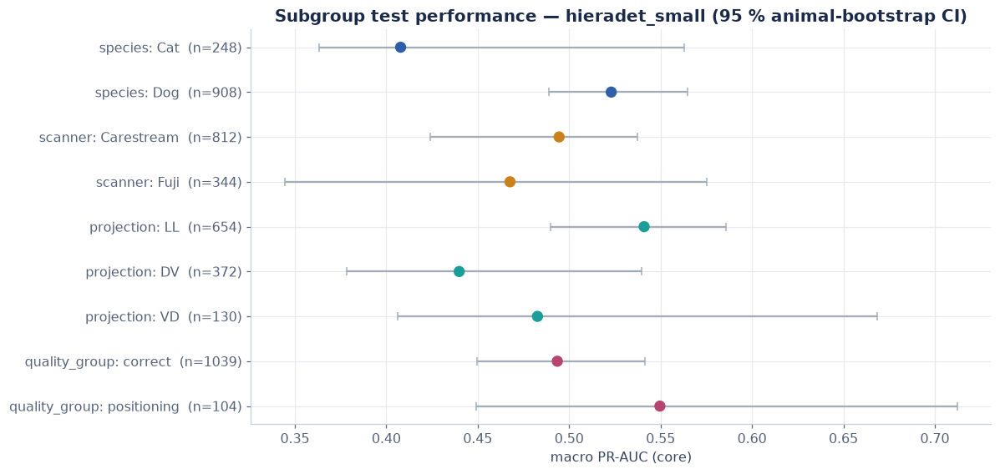

> Note: subgroups have different prevalences, and PR-AUC depends on prevalence. A lower PR-AUC in cats can partly reflect fewer positives, not only worse discrimination.

In [50]:
if selection and selection["run"] in TEST:
    tw = work[work.split == "test"].reset_index(drop=True)
    sub_rows = []
    for col in ["species", "scanner", "projection", "quality_group"]:
        for val in tw[col].dropna().unique():
            m = (tw[col] == val).values
            if m.sum() < 30: continue
            g = tw.loc[m, "group"].to_numpy()
            est = macro_ap_core(yt[m], pt[m])
            lo, hi = group_bootstrap_ci(yt[m], pt[m], g, macro_ap_core, n=500 if RUN_MODE == "FULL" else 30)
            sub_rows.append({"factor": col, "level": str(val), "images": int(m.sum()), "macro PR-AUC (core)": est, "lo": lo, "hi": hi})
    sub = pd.DataFrame(sub_rows)
    if len(sub):
        fig, ax = plt.subplots(figsize=(11, 0.42 * len(sub) + 1.5))
        yy = np.arange(len(sub))[::-1]
        cols = {"species": BLUE, "scanner": AMBER, "projection": TEAL, "quality_group": MAGENTA}
        ax.errorbar(sub["macro PR-AUC (core)"], yy, xerr=[sub["macro PR-AUC (core)"] - sub.lo, sub.hi - sub["macro PR-AUC (core)"]],
                    fmt="none", ecolor=GREY, capsize=3)
        ax.scatter(sub["macro PR-AUC (core)"], yy, c=[cols[c] for c in sub.factor], s=60, zorder=3)
        ax.set_yticks(yy, [f"{a}: {b}  (n={n})" for a, b, n in zip(sub.factor, sub.level, sub.images)])
        ax.set(title=f"Subgroup test performance — {selection['run']} (95 % animal-bootstrap CI)", xlabel="macro PR-AUC (core)")
        plt.tight_layout(); plt.show()
        display(Markdown("> Note: subgroups have different prevalences, and PR-AUC depends on prevalence. A lower PR-AUC in "
                         "cats can partly reflect fewer positives, not only worse discrimination."))

## 13 · Explainability and Error Analysis

**What Grad-CAM shows, and what it does not.** Grad-CAM weights the last spatial feature map by how strongly each
channel pushes a chosen finding's logit upward, producing a coarse heat map of *influential regions*. It is useful to
spot shortcuts (a heat map on a burned-in "D/S" marker or the collimator edge is a red flag). It is **not** a
segmentation: a highlighted region is not a validated lesion location.

In [51]:
class GradCAM:
    def __init__(self, model, layer, to_map=None):
        self.model, self.to_map, self.act, self.grad = model, to_map, None, None
        self.h = layer.register_forward_hook(self._hook)
    def _hook(self, mod, inp, out):
        out = out[0] if isinstance(out, (tuple, list)) else out
        self.act = out
        out.register_hook(lambda g: setattr(self, "grad", g))
    def __call__(self, x, j):
        self.model.zero_grad(set_to_none=True)
        logit = self.model(x)[0, j]; logit.backward()
        a, g = self.act, self.grad
        if self.to_map: a, g = self.to_map(a), self.to_map(g)
        w = g.mean(dim=(2, 3), keepdim=True)
        cam = F.relu((w * a).sum(1, keepdim=True))
        cam = F.interpolate(cam, size=x.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(logit).item()
    def close(self):
        self.h.remove()

def cam_layer(model, spec):
    bb = model.backbone
    if spec.name in ("custom_cnn", "custom_resnet"): return bb.stages[-1], None
    if spec.name == "efficientnet_b3": return bb.bn2, None
    if spec.name == "densenet121": return bb.features, None
    if spec.name == "convnext_tiny": return bb.stages[-1], None
    if spec.name == "hieradet_small": return bb.body, lambda t: t.permute(0, 3, 1, 2)
    if spec.name == "clip_vit_b32":
        def tok2map(t):
            t = t[:, 1:, :]; n = int(math.isqrt(t.shape[1]))
            return t.transpose(1, 2).reshape(t.shape[0], -1, n, n)
        return getattr(bb, "vision_model", bb).encoder.layers[-1], tok2map
    raise ValueError(spec.name)

[13/Oct/2026 09:08:27.0553 INFO fs_ops.py:644 ] Loading model from G:\VetXRay_cache\pretrained\hieradet_d_small_dino-v2-inat21.pt on device cpu...


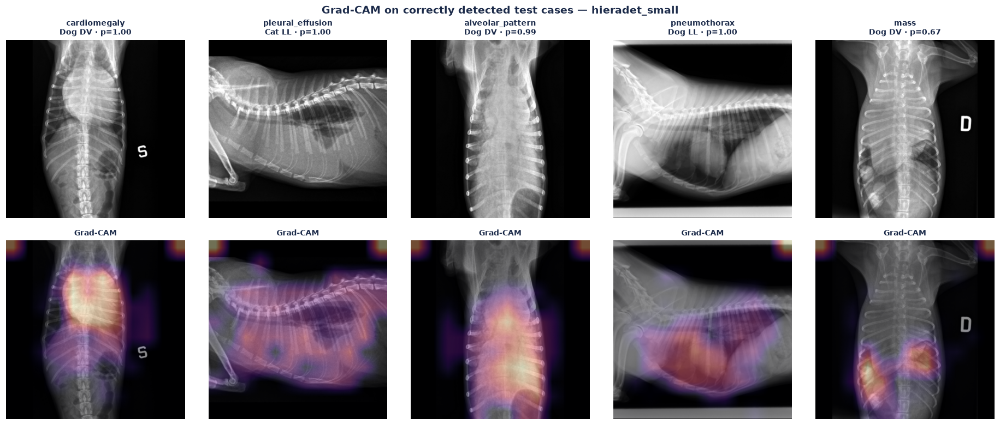

In [52]:
if selection and selection["run"] in TEST:
    model, spec, _ = load_trained(selection["run"])
    if spec.grad_ckpt and hasattr(model.backbone, "set_grad_checkpointing"):
        model.backbone.set_grad_checkpointing(False)
    layer, tmap = cam_layer(model, spec); cam = GradCAM(model, layer, tmap)
    tw = work[work.split == "test"].reset_index(drop=True); thr = VAL[selection["run"]][2]
    cases = []
    for f in ["cardiomegaly", "pleural_effusion", "alveolar_pattern", "pneumothorax", "mass", "megaesophagus"]:
        j = FINDINGS.index(f); tp_idx = np.flatnonzero((yt[:, j] == 1) & (pt[:, j] >= thr[j]))
        if len(tp_idx): cases.append((tp_idx[np.argmax(pt[tp_idx, j])], f))
    fig, axes = plt.subplots(2, max(1, len(cases)), figsize=(3.4 * max(1, len(cases)), 7.2), squeeze=False)
    for c, (i, f) in enumerate(cases):
        x = torch.from_numpy(np.ascontiguousarray(images[int(tw.loc[i, "row"])]))[None, None]
        xin = prepare(x, spec, False).requires_grad_(True)
        heat, prob = cam(xin, FINDINGS.index(f))
        base = F.interpolate(x.float(), size=(spec.input_size,) * 2, mode="bilinear", antialias=True)[0, 0].numpy()
        axes[0, c].imshow(base, cmap="gray"); axes[0, c].set_title(f"{f}\n{tw.loc[i, 'species']} {tw.loc[i, 'projection']} · p={prob:.2f}", fontsize=9)
        axes[1, c].imshow(base, cmap="gray"); axes[1, c].imshow(heat, cmap="magma", alpha=0.45); axes[1, c].set_title("Grad-CAM", fontsize=9)
    for a in axes.flat: a.axis("off")
    fig.suptitle(f"Grad-CAM on correctly detected test cases — {selection['run']}", color=NAVY, fontweight="bold")
    plt.tight_layout(h_pad=3.0); plt.show(); cam.close()

### 13.1 · Prediction gallery and error analysis

For each test image: ground truth, predicted findings, and the score of every finding the model flagged or missed.
**TP** = correctly flagged, **FP** = flagged but absent, **FN** = present but missed.

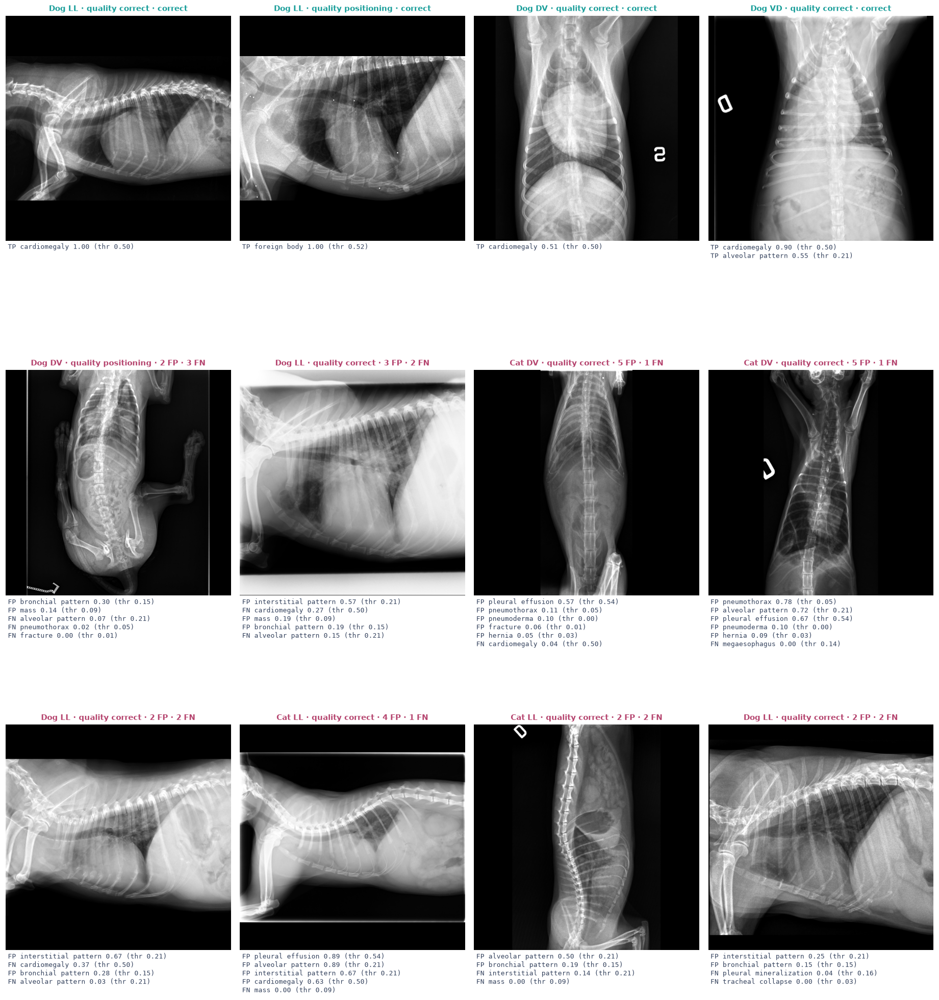

,mean errors / image,factor
correct,0.85,quality
exposure,0.54,quality
positioning,0.72,quality
0.000000,0.36,true findings (3 = 3+)
1.000000,1.16,true findings (3 = 3+)
2.000000,1.53,true findings (3 = 3+)
3.000000,2.00,true findings (3 = 3+)
Cat,1.17,species
Dog,0.75,species


In [53]:
def describe_case(i):
    j_true = set(np.flatnonzero(yt[i] == 1)); j_pred = set(np.flatnonzero(pt[i] >= thr))
    lines = []
    for j in sorted(j_true | j_pred, key=lambda j: -pt[i, j]):
        kind = "TP" if j in j_true and j in j_pred else ("FP" if j in j_pred else "FN")
        lines.append(f"{kind} {FINDINGS[j].replace('_', ' ')} {pt[i, j]:.2f} (thr {thr[j]:.2f})")
    return lines or ["TN: no finding, none predicted"]

if selection and selection["run"] in TEST:
    tw = work[work.split == "test"].reset_index(drop=True); thr = VAL[selection["run"]][2]
    fp_n = ((pt >= thr) & (yt == 0)).sum(1); fn_n = ((pt < thr) & (yt == 1)).sum(1); ok = (fp_n + fn_n) == 0
    rng_ = np.random.default_rng(SEED)
    pick = list(rng_.choice(np.flatnonzero(ok & (yt.sum(1) > 0)), min(4, (ok & (yt.sum(1) > 0)).sum()), replace=False)) + \
           list(np.argsort(-(fn_n * 2 + fp_n))[:8])
    fig, axes = plt.subplots(3, 4, figsize=(17, 18.5))
    for a, i in zip(axes.flat, pick):
        a.imshow(images[int(tw.loc[i, "row"])], cmap="gray"); a.axis("off")
        status = "correct" if ok[i] else f"{fp_n[i]} FP · {fn_n[i]} FN"
        a.set_title(f"{tw.loc[i, 'species']} {tw.loc[i, 'projection']} · quality {tw.loc[i, 'quality']} · {status}", fontsize=9.5,
                    color=TEAL if ok[i] else MAGENTA, fontweight="bold")
        a.text(0.01, -0.01, "\n".join(describe_case(i)[:6]), transform=a.transAxes, va="top", fontsize=8.2, family="monospace", color="#33415C")
    plt.tight_layout(h_pad=7.5); plt.show()

    err = pd.DataFrame({"quality": tw["quality_group"], "n_true": yt.sum(1), "errors": fp_n + fn_n, "species": tw["species"], "scanner": tw["scanner"]})
    agg = pd.concat([err.groupby("quality")["errors"].mean().rename("mean errors / image").to_frame().assign(factor="quality"),
                     err.groupby(err.n_true.clip(upper=3))["errors"].mean().rename("mean errors / image").to_frame().assign(factor="true findings (3 = 3+)"),
                     err.groupby("species")["errors"].mean().rename("mean errors / image").to_frame().assign(factor="species")])
    display(agg.style.format({"mean errors / image": "{:.2f}"}))

**Error analysis — what the evidence supports.** The table relates the number of errors per image to image quality,
to how many findings the film carries, and to species. Typical patterns to check in the output above: (1) films with
several concurrent findings produce more errors, consistent with overlapping opacities (effusion hiding a mass or the
cardiac silhouette); (2) positioning/exposure flags raise the error rate; (3) the rarest core findings contribute most
false negatives. Statements about individual images are only made where the table or the image supports them;
annotation noise cannot be quantified because the release has a single reader per image.

## 14 · Export of the PetAI Model and Inference Parity Test

The checkpoint contains only tensors and plain Python types, so it loads with `torch.load(..., weights_only=True)`
(no arbitrary code execution). It stores everything needed to reproduce inference exactly:
architecture and weight identifiers, label order, resolution, preprocessing parameters, normalisation, the
validation-fitted thresholds, and version information.

In [54]:
def export_petai(sel):
    model, spec, s = load_trained(sel["run"])
    arch = {"timm_id": TIMM_IDS.get(spec.name)}
    if spec.name == "clip_vit_b32":
        arch = {"hf_id": CLIP_ID, "config_json": model.backbone.config.to_json_string()}
    elif spec.name == "hieradet_small":
        arch = {"birder_net": HIERA_NET, "birder_weights": HIERA_WEIGHTS}
    thr = VAL[sel["run"]][2]
    ckpt = {"format_version": 1, "architecture": spec.name, "family": spec.family, "arch_config": arch,
            "state_dict": {k: v.detach().cpu() for k, v in model.state_dict().items()},
            "labels": list(FINDINGS), "core_labels": list(CORE), "thresholds": [float(t) for t in thr],
            "input_size": spec.input_size, "in_chans": spec.in_chans, "mean": list(spec.mean), "std": list(spec.std),
            "dropout": float(s["config"]["drop"]),
            "preprocessing": {"version": PREPROCESS_VERSION, "cache_size": CACHE_SIZE, "pct_low": PCT_LOW, "pct_high": PCT_HIGH,
                              "letterbox": "lanczos, centred, zero padding", "resize": "bilinear antialias"},
            "model_version": f"petai-xray-{spec.name}-{time.strftime('%Y%m%d')}", "run": sel["run"], "mode": RUN_MODE,
            "dataset_version": "VetXRay v2, Zenodo 10.5281/zenodo.19051776 (CC BY 4.0)",
            "validation_macro_PR_AUC_core": float(sel["val_macro_PR_AUC_core"]),
            "library_versions": {p: _ver(p) for p in ["torch", "timm", "transformers", "birder", "pydicom", "numpy", "Pillow"]}}
    PETAI_CKPT.parent.mkdir(parents=True, exist_ok=True)
    torch.save(ckpt, PETAI_CKPT)
    return model, spec

if selection and RUN_MODE == "FULL":
    petai_model, petai_spec = export_petai(selection)
    print(f"saved {PETAI_CKPT} ({PETAI_CKPT.stat().st_size/1e6:.1f} MB)")
elif selection:
    print("SMOKE mode: the PetAI checkpoint is NOT written to the project (no scientific selection was made).")
    petai_model, petai_spec = None, None

[13/Oct/2026 09:08:31.0978 INFO fs_ops.py:644 ] Loading model from G:\VetXRay_cache\pretrained\hieradet_d_small_dino-v2-inat21.pt on device cpu...


saved G:\Vet_XRay_AI\checkpoints\petai_xray_best.pt (135.9 MB)


**Parity test.** The inference module is imported from the project folder and run on test DICOMs straight from the
archives. Its probabilities must match the notebook pipeline (same weights, same preprocessing, float32 on both sides).

In [55]:
inf_path = PROJECT_DIR / "petai_xray_inference.py"
if selection and inf_path.exists():
    spec_mod = importlib.util.spec_from_file_location("petai_xray_inference", inf_path)
    petai = importlib.util.module_from_spec(spec_mod); spec_mod.loader.exec_module(petai)
    if RUN_MODE == "SMOKE":
        # write a temporary checkpoint outside the project to exercise the module end-to-end
        smoke_ckpt = WORK_DIR / "smoke_petai_ckpt.pt"
        _orig = PETAI_CKPT; PETAI_CKPT = smoke_ckpt; petai_model, petai_spec = export_petai(selection); PETAI_CKPT = _orig
        ckpt_for_test = smoke_ckpt
    else:
        ckpt_for_test = PETAI_CKPT
    tmp = WORK_DIR / "parity_tmp"; tmp.mkdir(exist_ok=True)
    names = work[work.split == "test"].FileName.head(3).tolist()
    rows = []
    petai_model = petai_model.float().eval()
    for n in names:
        if CACHE_ONLY:   # no DICOMs: check checkpoint rebuild + tensor path of the module on the cached uint8 image
            m_, ck_, dv_ = petai._load(str(ckpt_for_test), str(DEVICE))
            with torch.no_grad():
                pr_ = torch.sigmoid(m_(petai._to_tensor(load_cached_style(n), ck_, dv_)).float())[0].cpu().numpy()
            out = {"findings": {f: {"score": float(v)} for f, v in zip(ck_["labels"], pr_)},
                   "positive_findings": [f for f, v, th in zip(ck_["labels"], pr_, ck_["thresholds"]) if v >= th]}
        else:
            p_ = tmp / n
            with src.open(n) as fh: p_.write_bytes(fh.read())
            out = petai.predict(str(p_), checkpoint=str(ckpt_for_test), device=str(DEVICE))
        with torch.no_grad():
            x = torch.from_numpy(load_cached_style(n))[None, None]
            ref = torch.sigmoid(petai_model(prepare(x, petai_spec, False).float())).cpu().numpy()[0]
        got = np.array([out["findings"][f]["score"] for f in FINDINGS])
        rows.append({"file": n, "max |Δ probability|": float(np.abs(got - ref).max()), "positives (module)": out["positive_findings"]})
    parity = pd.DataFrame(rows); display(parity)
    assert parity["max |Δ probability|"].max() < 1e-4, "inference module does not reproduce the notebook pipeline"
    print("PASS: petai_xray_inference.py reproduces the notebook predictions"
          + (" (cache-level check; DICOM-preprocessing parity is verified in the local run)" if CACHE_ONLY else ""))
    print(json.dumps({k: v for k, v in out.items() if k != "findings"}, indent=1))

,file,max |Δ probability|,positives (module)
0,IM-0015-0001-0008.dcm,4.768951e-07,[bronchial_pattern]
1,IM-0015-0001-0056.dcm,4.049696e-07,[]
2,IM-0015-0001-0065.dcm,3.692720e-07,[]


PASS: petai_xray_inference.py reproduces the notebook predictions
{
 "status": "ok",
 "model_name": "HieraDet-D Small",
 "model_version": "petai-xray-hieradet_small-20261013",
 "dataset_version": "VetXRay v2, Zenodo 10.5281/zenodo.19051776 (CC BY 4.0)",
 "num_labels": 17,
 "labels": [
  "alveolar_pattern",
  "bronchial_pattern",
  "cardiomegaly",
  "costal_fracture",
  "diaphragmatic_hernia",
  "foreign_body",
  "fracture",
  "hernia",
  "interstitial_pattern",
  "mass",
  "megaesophagus",
  "pleural_effusion",
  "pleural_mineralization",
  "pneumoderma",
  "pneumomediastinum",
  "pneumothorax",
  "tracheal_collapse"
 ],
 "positive_findings": [],
 "input": {
  "file": "IM-0015-0001-0065.dcm",
  "type": "dicom",
  "preprocessing": "vxr-pre-1.0",
  "model_input_size": 384
 },
 "device": "cuda",
 "disclaimer": "Research model for decision support experiments; not a validated diagnostic device."
}


## 15 · Discussion, Limitations and Conclusion

In [56]:
if len(test_table):
    best_run = test_table["test macro PR-AUC (core)"].idxmax()
    lines = [f"* Best test macro PR-AUC (core): **{best_run}** = {test_table.loc[best_run, 'test macro PR-AUC (core)']:.3f} "
             f"(95 % CI {test_table.loc[best_run, '95% CI']})."]
    if selection and selection["run"] in test_table.index:
        lines.append(f"* Selected PetAI model (chosen on validation before testing): **{selection['run']}**, test macro PR-AUC (core) = "
                     f"{test_table.loc[selection['run'], 'test macro PR-AUC (core)']:.3f}, macro ROC-AUC = "
                     f"{test_table.loc[selection['run'], 'test macro ROC-AUC (core)']:.3f}.")
    for c in ["custom_cnn", "custom_resnet"]:
        if c in test_table.index:
            lines.append(f"* {c}: {test_table.loc[c, 'test macro PR-AUC (core)']:.3f} — gap to the best pretrained model quantifies the value of pretraining at this data scale.")
    if RUN_MODE == "SMOKE":
        lines.insert(0, "**SMOKE MODE — the numbers below verify the code path only and carry no scientific meaning.**")
    display(Markdown("\n".join(lines)))

* Best test macro PR-AUC (core): **hieradet_small** = 0.492 (95 % CI 0.430–0.534).
* Selected PetAI model (chosen on validation before testing): **hieradet_small**, test macro PR-AUC (core) = 0.492, macro ROC-AUC = 0.874.
* custom_cnn: 0.328 — gap to the best pretrained model quantifies the value of pretraining at this data scale.
* custom_resnet: 0.347 — gap to the best pretrained model quantifies the value of pretraining at this data scale.

**Limitations (independent of the final numbers)**

1. **Single institution.** All images come from one teaching hospital. Two acquisition systems are present, but no
   external clinic was available; performance on other hospitals, breeds mixes and DR detectors is unknown.
2. **Rare findings.** Seven findings have fewer than 70 positive images. The model outputs a probability for them, but
   no claim about their accuracy is supported; their thresholds default to 0.5 when validation has no positives.
3. **Single reader per image.** Label noise cannot be estimated; inter-observer variability in radiology is substantial
   for patterns such as interstitial vs bronchial.
4. **Image-level, single-view model.** Radiologists read lateral and DV/VD views together; this model sees one view at
   a time. Multi-view fusion per study is a natural next step.
5. **Grouping is conservative, not perfect.** Animals are linked by PatientID and by name+breed+species; an animal
   registered under two IDs and two names would escape detection.
6. **Scanner confound.** Scanner, era and case mix are partly correlated; subgroup results (§12.5) should be read with
   this in mind.
7. **Not a medical device.** The exported model is a research artefact for decision support experiments. It must not
   be used for diagnosis without prospective veterinary validation.

**Possible improvements:** multi-view (study-level) models; higher resolution (512 px) for subtle patterns;
domain-specific self-supervised pretraining on unlabelled veterinary radiographs; ensembling across seeds (outside the
single-model PetAI constraint); external validation on another clinic's data.

**Data licence and attribution.** VetXRay is released under CC BY 4.0 by Banzato, Burti, Zotti and Wodzinski
(University of Padua). No DICOM files or identifying metadata are redistributed by this notebook.

### References

1. Banzato T, Wodzinski M, Burti S, et al. Automatic classification of canine thoracic radiographs using deep learning. *Sci Rep* 11:3964 (2021). https://pmc.ncbi.nlm.nih.gov/articles/PMC7889925
2. Banzato T, Wodzinski M, Tauceri F, et al. An AI-based algorithm for the automatic classification of thoracic radiographs in cats. *Front Vet Sci* 8:731936 (2021). https://pmc.ncbi.nlm.nih.gov/articles/PMC8554083
3. Banzato T, Wodzinski M, Burti S, et al. An AI-based algorithm for the automatic evaluation of image quality in canine thoracic radiographs. *Sci Rep* 13 (2023). https://pmc.ncbi.nlm.nih.gov/articles/PMC10562412
4. Burti S, Longhin Osti V, Zotti A, Banzato T. Use of deep learning to detect cardiomegaly on thoracic radiographs in dogs. *Vet J* (2020). https://research.unipd.it/handle/11577/3348309
5. VetXRay dataset, Zenodo (2026). https://doi.org/10.5281/zenodo.19051776 · utilities: https://github.com/MWod/VetXRay_Dataset
6. Radford A, et al. Learning transferable visual models from natural language supervision (CLIP). arXiv:2103.00020
7. Ryali C, et al. Hiera: A hierarchical vision transformer without the bells-and-whistles. arXiv:2306.00989
8. Oquab M, et al. DINOv2: Learning robust visual features without supervision. arXiv:2304.07193
9. Tan M, Le Q. EfficientNet: Rethinking model scaling for CNNs. ICML 2019. https://proceedings.mlr.press/v97/tan19a.html
10. Huang G, et al. Densely connected convolutional networks. arXiv:1608.06993
11. Liu Z, et al. A ConvNet for the 2020s. arXiv:2201.03545
12. He K, et al. Deep residual learning for image recognition. arXiv:1512.03385
13. Hu J, et al. Squeeze-and-excitation networks. arXiv:1709.01507
14. Selvaraju RR, et al. Grad-CAM: Visual explanations from deep networks via gradient-based localization. arXiv:1610.02391
15. Sechidis K, Tsoumakas G, Vlahavas I. On the stratification of multi-label data. ECML PKDD 2011.
16. Godbole V, et al. Deep Learning Tuning Playbook. https://github.com/google-research/tuning_playbook
17. Akiba T, et al. Optuna: A next-generation hyperparameter optimization framework. KDD 2019. https://optuna.readthedocs.io/
18. Birder library and model card: https://github.com/birder-project/birder · https://huggingface.co/birder-project/hieradet_d_small_dino-v2-inat21